# Project 1: VaR and ES -- Estimation, Backtesting, and Model Comparison

**Names of all group members:**
- Dario Frey (dario.frey@epfl.ch)
- Léo Wunderli (leo.wunderli@epfl.ch)
- Romain Fastenaekels (romain.fastenaekels@epfl.ch)
- Enzo Cassini-Peloux (enzo.cassini-peloux@epfl.ch)
---

## Report reproducibility and cross-reference

The table below identifies the notebook sections associated
with each figure and table in the submitted report.

| Report elements | Notebook section |
|---|---|
| Figures 1–3, Tables 1–2 | Question 1 — Stylized facts |
| Figure 4, Tables 3–4 | Question 2 — Single-window VaR and ES estimates |
| Table 5 | Question 3(d) — FZ scores and DM test |
| Tables 6–8 | Question 4(a) — AR model selection and diagnostics |
| Tables 9–10 | Question 4(b) — Full-sample AR-GARCH estimation |
| Table 11 | Question 4(d) — FZ scores and DM test |
| Table 12 | Question 5(b) — Quantile regression comparison |
| Figures 5–6 | Question 6(b–c) — Mean excess and GPD fitting |
| Tables 13–14 | Question 6(d–e) — Deep-tail risk estimates |
| Table 15 | Question 7 — Recommendation |
| Tables 16–17 | Question 5 — Combined VaR backtests |
| Table 18 | Question 4(d) — Combined ES backtests |

To reproduce the numerical results and figures, place
`QRM_2026_Project_prices.csv` in the notebook directory
and execute all cells sequentially from a fresh kernel.
The random seed is fixed at 0.

## 0) Setup

Creates necessary folders, sets parameters, and fixes the random seed. Keep this seed fixed; the whole run must be reproducible from it.

In [1]:
# If a package import fails, install it in your environment, e.g.:
# %pip install arch statsmodels

import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-darkgrid")
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_FILE = PROJECT_DIR / "QRM_2026_Project_prices.csv"   # provided with the project; do not re-download
OUT_DIR = PROJECT_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

STOCK_COLORS = {"AAPL": "steelblue", "META": "indianred", "JPM": "darkseagreen"}
METHOD_COLORS = {"Historical": "steelblue", "Gaussian": "indianred",
                 "Student-t": "darkseagreen", "Fitted GPD": "slateblue"}

# Parameters
TICKERS = ["AAPL", "META", "JPM"]   # every question is run separately on each stock
WINDOW = 504                        # estimation window of every model, in trading days (Questions 2-5)
EVAL_START = 504                    # Questions 3-5: forecast days are all days after the first 504
REFIT = 21                          # Questions 4-5: re-estimate every this many trading days
ALPHAS = [0.975, 0.99]              # confidence levels used throughout Questions 2-5
DEEP_ALPHA = 0.999                  # Question 6: the extreme level EVT is asked for
M_SIM = 10_000                      # Questions 3(c), 4(d): Acerbi-Szekely simulated samples
LB_LAGS = 10                        # Ljung-Box H in Questions 1 and 4
NW_LAGS = 10                        # Newey-West truncation lag of the Diebold-Mariano test
SEED = 0                            # fix this, state it in the report, do not change it later

rng = np.random.default_rng(SEED)
print("Project dir:", PROJECT_DIR)


Project dir: /Users/romain/Documents/Epfl/MA3/quant_risk/QRM_project


## 1) Data

The prices were downloaded once with `yfinance` (adjusted closes, 2 January 2013 to 30 June 2026,
downloaded on 28 October 2026) and are provided as `QRM_2026_Project_prices.csv`. Read this file;
do not download the data again, since Yahoo revises adjusted prices back in time.

In [2]:
price_df = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)[TICKERS]
print(price_df.shape, price_df.index[0].date(), "to", price_df.index[-1].date())   # (3393, 3)

(3393, 3) 2013-01-02 to 2026-06-30


## 2) Log-returns and losses

Construct $R_t=\log(P_t/P_{t-1})$ for each ticker. The log-loss used everywhere in this project is
$L_t=-R_t$. Every question is run separately on each of the three columns; there is no portfolio.

In [3]:
returns = np.log(price_df / price_df.shift(1)).dropna()
losses = -returns

print(returns.shape, returns.index[0].date(), "to", returns.index[-1].date())   # (3392, 3)
returns.head()

(3392, 3) 2013-01-03 to 2026-06-30


,AAPL,META,JPM
Date,,,
2013-01-03,-0.012703,-0.008248,-0.002017
2013-01-04,-0.028250,0.035029,0.017569
2013-01-07,-0.005900,0.022689,0.001101
2013-01-08,0.002688,-0.012312,0.001980
2013-01-09,-0.015752,0.051311,-0.000660


## Question 1 -- Stylized facts

For each stock: (a) plot the return series; (b) ACF of returns and of squared returns, and the
Ljung-Box test with $H$ = `LB_LAGS` on both (`statsmodels.stats.diagnostic.acorr_ljungbox`);
(c) QQ-plot and Jarque-Bera.

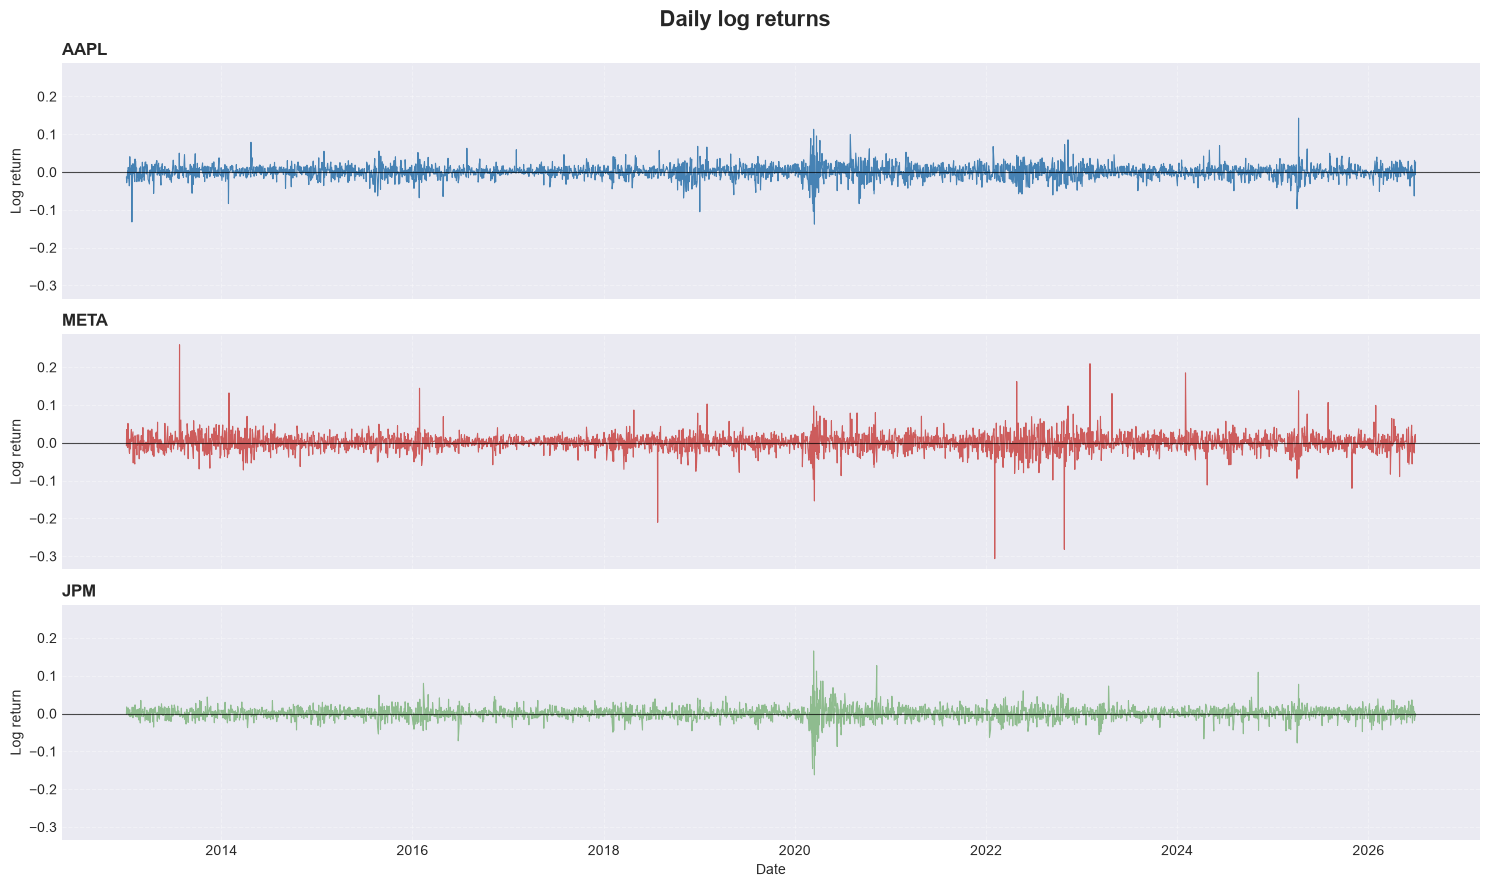

In [4]:
# Question 1

# (a)
n_series = returns.shape[1]
fig, axes = plt.subplots(
    n_series, 1,
    figsize=(15, 3 * n_series),
    sharex=True,
    sharey=True
)

fig.suptitle("Daily log returns", fontsize=16, fontweight="bold")

for ax, column in zip(axes, TICKERS):
    ax.plot(returns.index, returns[column], linewidth=0.8, color=STOCK_COLORS[column])
    ax.axhline(0, color="black", linewidth=0.8, alpha=0.7)
    ax.set_title(column, loc="left", fontsize=12, fontweight="bold")
    ax.set_ylabel("Log return")
    ax.grid(True, linestyle="--", alpha=0.35)

axes[-1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(OUT_DIR / "Q1_1-stylizedfacts.png", dpi=300)
plt.show()

Volatility rises for all three stocks during the March 2020 COVID-19 market shock, most visibly for JPM. META also has a stock-specific move on 3 February 2022, when its log return is about $-0.306$, much larger than the other two stocks' moves that day.

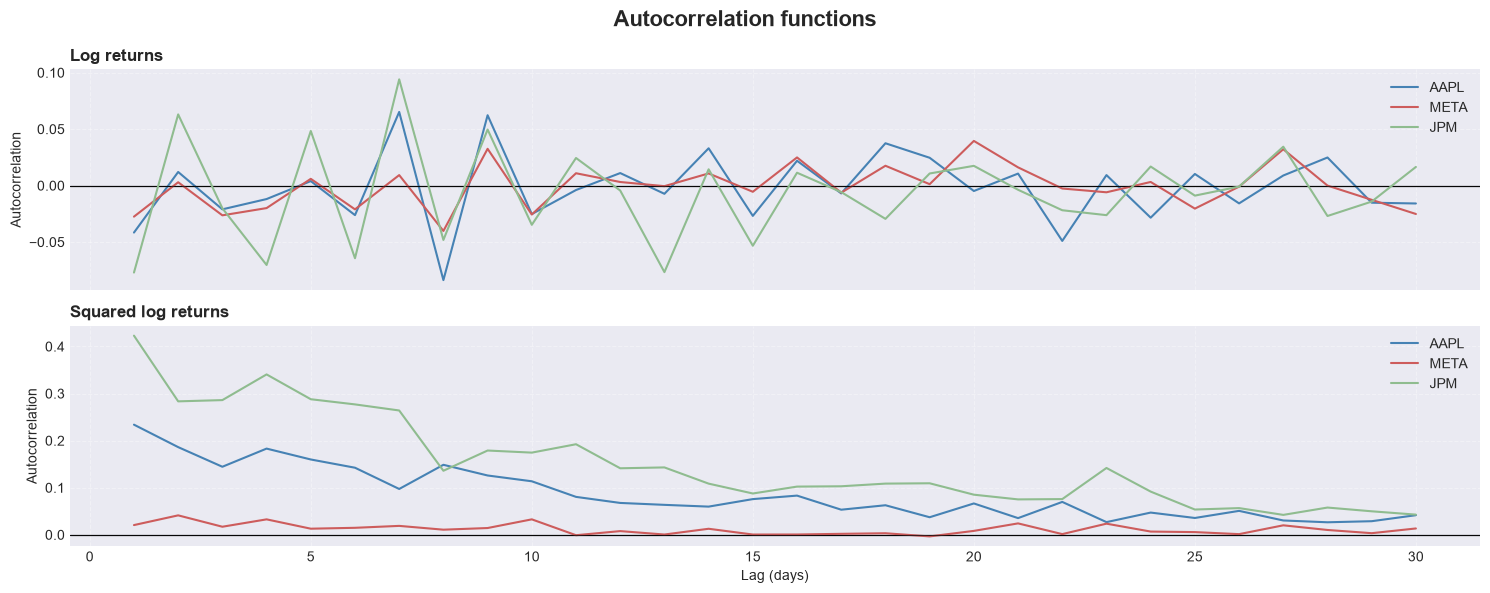

Ljung-box test - returns


,AAPL,META,JPM
lb_stat,6.443005e+01,19.576186,1.242931e+02
lb_pvalue,5.209219e-10,0.033526,6.791373e-22


Ljung-box test - squared returns


,AAPL,META,JPM
lb_stat,8.492934e+02,19.097453,2607.492719
lb_pvalue,5.179304e-176,0.039042,0.000000


In [5]:
# (b)
# We use the statsmodels acf and acorr_ljungbox methods
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

ACF = {}
ljung = {}
ljung_squared = {}

for elem in returns:
    ret = returns[elem]
    ret_2 = returns[elem] ** 2
    
    # Ljung-box test
    lj1 = acorr_ljungbox(ret, lags=[LB_LAGS]) 
    lj2 = acorr_ljungbox(ret_2, lags=[LB_LAGS])
    ljung[elem] = lj1.values.reshape(-1,)
    ljung_squared[elem] = lj2.values.reshape(-1,)
    
    acf_ret = acf(ret, nlags = 30, result_object = True)
    acf_ret_2 = acf(ret_2, nlags = 30, result_object = True)
    
    ACF[elem] = [acf_ret, acf_ret_2]
    
fig, axes = plt.subplots(
    2, 1, 
    sharex = True,
    figsize = (15, 2 * 3)
)

fig.suptitle("Autocorrelation functions", fontsize=16, fontweight="bold")

for index, (name, value) in enumerate(ACF.items()):
    h = np.arange(1, 31, 1)
    
    for i in range(2):
        ax = axes[i]
        ax.axhline(0, color="black", linewidth=0.8, alpha=0.7)
        ax.grid(True, linestyle="--", alpha=0.35)
        
        val = value[i].acf
        ax.plot(h, val[1:], label = name, color=STOCK_COLORS[name])
        ax.legend()
    
axes[0].set_title("Log returns", loc="left", fontsize=12, fontweight="bold")
axes[1].set_title("Squared log returns", loc="left", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Lag (days)")
for ax in axes:
    ax.set_ylabel("Autocorrelation")
plt.tight_layout()
fig.savefig(OUT_DIR / "Q1_2-ACF.png", dpi=300)
plt.show()
    
print('Ljung-box test - returns')
display(pd.DataFrame(ljung, index=['lb_stat', 'lb_pvalue']))
print('Ljung-box test - squared returns')
display(pd.DataFrame(ljung_squared, index=['lb_stat', 'lb_pvalue']))


The Ljung–Box test checks whether autocorrelations at lags 1 through 10 are jointly zero. We apply it separately to log returns and squared log returns. 

Rejection for returns indicates linear serial autocorrelation. Rejection for squared returns indicates dependence in return magnitudes, consistent with volatility clustering. Individual return autocorrelations near zero do not imply independent returns: their squares can still be serially dependent. We reject the null hypothesis at the 5% significance level when the p-value is below 0.05.

The ACF plots suggest weaker serial dependence for META than for AAPL and JPM. This is consistent with META’s Ljung–Box p-values being closer to the 0.05 threshold for both returns and squared returns. Nevertheless, all six p-values are below 0.05, so we reject the joint hypothesis that autocorrelations at lags 1 through 10 are zero for every stock and both series.

The ACF of log returns fluctuates around zero, with positive and negative values across the 30 lags. For squared log returns, autocorrelations are mostly positive and generally decline as the lag increases. This pattern is clear for AAPL and JPM, but weaker and less regular for META, consistent with its higher p-value. It is consistent with volatility clustering that fades over time. The usual Ljung–Box reference distribution for squared returns requires a finite fourth moment; the fitted tails in Question 6 cast doubt on that condition for META and JPM, so those squared-return p-values need caution.

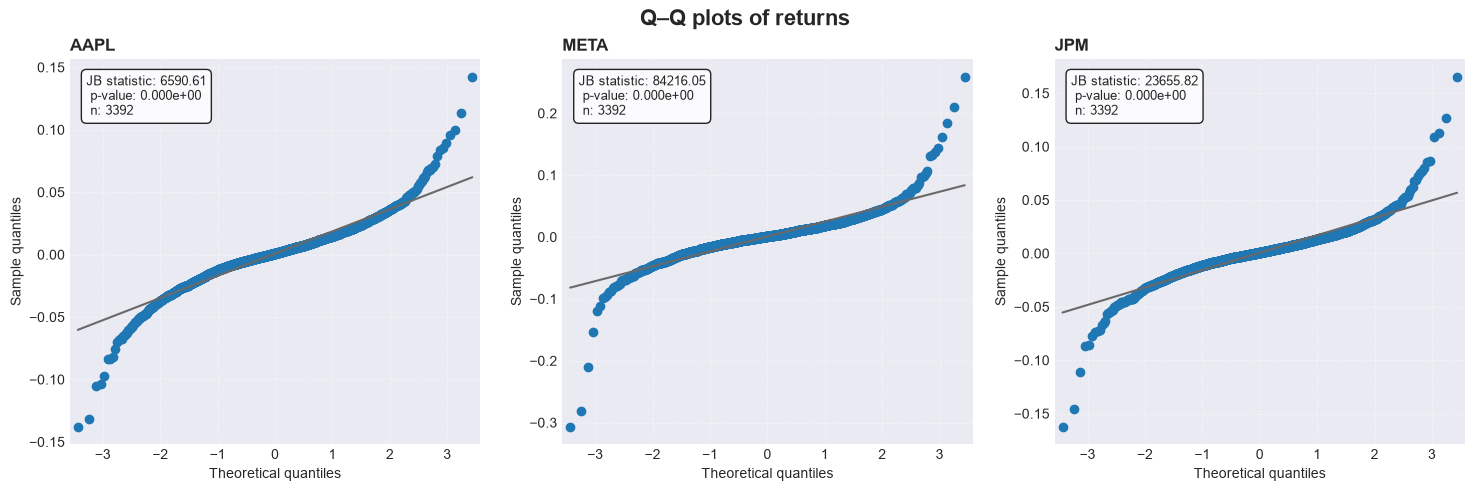

In [6]:
# (c) 
# 1. Q-Q plot
from statsmodels.graphics.gofplots import qqplot
from statsmodels.stats.stattools import jarque_bera

fig, axes = plt.subplots(
    1, 3, 
    figsize=(18, 5)
)
fig.suptitle("Q–Q plots of returns", fontsize=16, fontweight="bold")

for ax, column in zip(axes, TICKERS):
    data = returns[column].dropna()
    jb_stat, jb_pvalue, skew, kurt = jarque_bera(data)

    qqplot(data, line="s", ax=ax)
    ax.lines[0].set_color(STOCK_COLORS[column])
    ax.lines[1].set_color("dimgray")
    ax.set_title(column, loc="left", fontsize=12, fontweight="bold")
    ax.set_xlabel("Theoretical quantiles")
    ax.set_ylabel("Sample quantiles")
    ax.grid(True, linestyle="--", alpha=0.35)

    ax.text(
        0.04, 0.96,
        f"JB statistic: {jb_stat:.2f}\n p-value: {jb_pvalue:.3e}\n n: {len(data)}",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.85),
    )

fig.savefig(OUT_DIR / "Q1_3-QQplot.png", dpi=300)
plt.show()


The Jarque–Bera test assesses normality using the skewness and kurtosis of returns. Under the test assumptions, its null hypothesis is that returns are i.i.d. normally distributed (skewness of 0 and kurtosis of 3). 

For all three stocks, the p-values are below 0.05, so we reject normality at the 5% significance level. We can observe on the QQ-plot that the tails of the returns diverge heavily from a normal distribution. This is consistent with the heavy tail behavior of stock returns.

## Question 2 -- Single-window VaR and ES estimates

For each stock, use the first `WINDOW` losses as the single estimation window for (a)-(d).

VaR      ES
alpha stock method                    
0.975 AAPL  Gaussian    3.068%  3.673%
            Historical  2.901%  4.974%
            Student-t   2.947%  4.249%
      JPM   Gaussian    2.198%  2.637%
            Historical  2.383%  2.921%
            Student-t   2.244%  2.987%
      META  Gaussian    4.720%  5.669%
            Historical  4.235%  5.596%
            Student-t   4.541%  6.351%
0.990 AAPL  Gaussian    3.655%  4.198%
            Historical  3.888%  7.389%
            Student-t   3.993%  5.555%
      JPM   Gaussian    2.623%  3.017%
            Historical  2.778%  3.536%
            Student-t   2.889%  3.694%
      META  Gaussian    5.640%  6.492%
            Historical  5.348%  6.530%
            Student-t   6.034%  8.138%

,AAPL,META,JPM
nu,4.132389,4.679262,6.482710
mu,-0.001059,-0.001308,-0.000962
sigma,0.011133,0.017800,0.009737


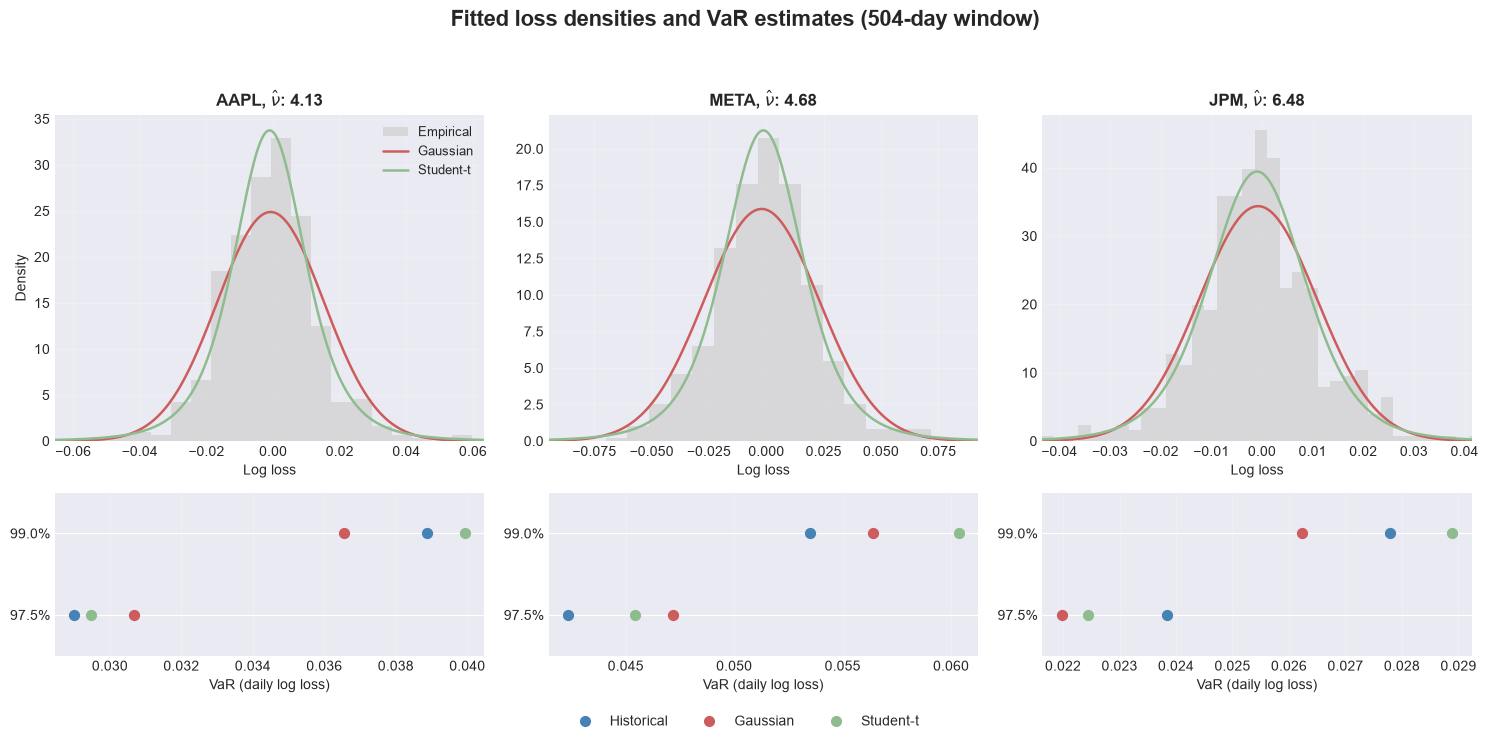

In [7]:
# Question 2
METHODS = ("Historical", "Gaussian", "Student-t")
window_losses = losses.iloc[:WINDOW]          # one column per stock

def historical_var_es(loss_window, alpha):
    """Returns VaR and ES at the alpha level using the historical simulation method."""
    loss_window = np.sort(loss_window)[::-1] 
    m = len(loss_window) * (1 - alpha)
    k = int(np.floor(m))
    var = loss_window[k]
    es = (loss_window[:k].sum() + (m - k) * var) / m
    return var, es

def gaussian_var_es(loss_window, alpha):
    """Returns VaR and ES at the alpha level using the gaussian estimation."""
    mu, sigma = loss_window.mean(), loss_window.std(ddof=1)
    z = stats.norm.ppf(alpha)
    var = mu + sigma * z
    es = mu + sigma * stats.norm.pdf(z) / (1 - alpha)
    return var, es

def student_t_var_es(nu, mu, sig, alpha):
    """Returns VaR and ES at the alpha level using the student-t estimation."""
    q = stats.t.ppf(alpha, nu)
    var = mu + sig * q
    es = mu + sig * stats.t.pdf(q, nu) / (1 - alpha) * (nu + q**2) / (nu - 1)
    return var, es

t_params = {s: stats.t.fit(window_losses[s].to_numpy(), method="MLE") for s in TICKERS}

# (a), (b) and (c)
rows = []
for stock in TICKERS:
    loss = window_losses[stock]
    nu, mu_t, sig_t = t_params[stock]
    for alpha in ALPHAS:
        measures = {
            "Historical": historical_var_es(loss, alpha),
            "Gaussian": gaussian_var_es(loss, alpha),
            "Student-t": student_t_var_es(nu, mu_t, sig_t, alpha),
        }
        for method, (var, es) in measures.items():
            rows.append({"method": method, "stock": stock,
                         "alpha": alpha, "VaR": var, "ES": es})

results_df = pd.DataFrame(rows)
t_params_df = pd.DataFrame(t_params, index=["nu", "mu", "sigma"])
display(results_df.set_index(["alpha", "stock", "method"]).sort_index().map(lambda p: f"{p:.3%}"))
display(t_params_df)

# (d) Fitted densities and VaR estimates, shown separately for clarity.
from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(
    2, 3, 
    figsize=(15, 7.5),
    gridspec_kw={"height_ratios": [2, 1]}
)
fig.suptitle("Fitted loss densities and VaR estimates (504-day window)", fontsize=16, fontweight="bold")

lookup = results_df.set_index(["stock", "alpha", "method"])
colors = METHOD_COLORS

for col, stock in enumerate(TICKERS):
    loss = window_losses[stock]
    nu, mu_t, sig_t = t_params[stock]

    left = min(stats.norm.ppf(0.002, loss.mean(), loss.std(ddof=1)), stats.t.ppf(0.002, nu, mu_t, sig_t))
    right = max(stats.norm.ppf(0.998, loss.mean(), loss.std(ddof=1)), stats.t.ppf(0.998, nu, mu_t, sig_t))
    grid = np.linspace(left, right, 400)

    density_ax = axes[0, col]
    density_ax.hist(loss, bins=35, density=True, color="lightgray", alpha=0.8,
                    label="Empirical")
    density_ax.plot(grid, stats.norm.pdf(grid, loss.mean(), loss.std(ddof=1)),
                    color=colors["Gaussian"], lw=1.8, label="Gaussian")
    density_ax.plot(grid, stats.t.pdf(grid, nu, mu_t, sig_t),
                    color=colors["Student-t"], lw=1.8, label="Student-t")
    density_ax.set_xlim(left, right)
    nu = t_params_df.loc["nu", stock]
    density_ax.set_title(rf"{stock}, $\hat\nu$: {nu:.2f}", fontsize=12, fontweight="bold")
    density_ax.set_xlabel("Log loss")
    density_ax.set_ylabel("Density" if col == 0 else "")
    density_ax.grid(True, alpha=0.2)

    var_ax = axes[1, col]
    for row, alpha in enumerate(ALPHAS):
        for method in METHODS:
            var = lookup.loc[(stock, alpha, method), "VaR"]
            var_ax.scatter(var, row, color=colors[method], s=50, zorder=3)
    var_ax.set_yticks(range(len(ALPHAS)), [f"{alpha:.1%}" for alpha in ALPHAS])
    var_ax.set_ylim(-0.5, len(ALPHAS) - 0.5)
    var_ax.set_xlabel("VaR (daily log loss)")
    var_ax.grid(axis="x", alpha=0.2)
    if stock == "META":
        var_ax.xaxis.set_major_locator(MaxNLocator(4)) # was to hard to read the x values otherwise

axes[0, 0].legend(fontsize=9)
handles = [plt.Line2D([], [], color=colors[method], marker="o", linestyle="None",
                      markersize=7, label=method) for method in METHODS]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 0.005))
fig.tight_layout(rect=(0, 0.05, 1, 0.94))
fig.savefig(OUT_DIR / "Q2_VaR.png", dpi=300)
plt.show()


At $\alpha=0.975$, Gaussian VaR is largest for AAPL and META, while Historical is largest for JPM. At $\alpha=0.99$, Student-t is largest for all three. Gaussian is smallest for AAPL and JPM; for META the order is Historical (5.348%), Gaussian (5.640%), Student-t (6.034%).

A smaller Student-t degrees-of-freedom parameter $\nu$ means heavier polynomial tails. The fitted Student-t scale parameter is not its standard deviation; for $\nu>2$, the standard deviation is the scale multiplied by $\sqrt{\nu/(\nu-2)}$. The fitted density is more peaked near the center than the Gaussian and has heavier far tails. Their curves cross, so Student-t VaR can be higher at 99% without necessarily being higher at 97.5%. JPM has the lightest fitted Student-t tail ($\hat\nu=6.48$), and the two parametric fits are closer there.

## Question 3 -- Backtesting

Forecast every day of the evaluation period `losses.iloc[EVAL_START:]`, each model estimated on the
`WINDOW` days before the forecast day. Historical simulation, Gaussian and Student-$t$ are recomputed
every day. Write the Kupiec, Christoffersen, Acerbi-Szekely, Fissler-Ziegel, pinball-loss and
Diebold-Mariano functions yourself, from the course slides (Kupiec, Christoffersen) and Appendix A of
the project statement (the others); they are
reused unchanged in Questions 4 and 5.

The combined VaR backtest table collects the VaR backtests of Questions 3-5: append one row per
stock, method and level to `backtest_rows` as you go. The ES backtest table ($\alpha=0.975$) collects
the Acerbi-Szekely and Fissler-Ziegel results of Questions 3 and 4 in `es_rows`.

In [8]:
from scipy.stats import chi2

def _term(k, q):
    return k * np.log(q) if k > 0 else 0.0

def kupiec(I, alpha):
    n, x = len(I), I.sum()
    phat, p = x / n, 1 - alpha
    lr = 2 * (_term(x, phat / p) + _term(n - x, (1 - phat) / (1 - p)))
    return lr, chi2.sf(lr, 1)

def christoffersen(I, alpha):
    I = np.asarray(I)
    prev, curr = I[:-1], I[1:]
    n00 = int(((prev==0) & (curr==0)).sum())
    n01 = int(((prev==0) & (curr==1)).sum())
    n10 = int(((prev==1) & (curr==0)).sum())
    n11 = int(((prev==1) & (curr==1)).sum())
    p01, p11 = n01 / (n00 + n01) if (n00 + n01) > 0 else 0.0, n11 / (n10 + n11) if (n10 + n11) > 0 else 0.0
    ppool = (n01 + n11) / (n00 + n01 + n10 + n11)
    l0 = _term(n01 + n11, ppool) + _term(n00 + n10, 1 - ppool)
    l1 = _term(n01, p01) + _term(n00, 1 - p01) + _term(n11, p11) + _term(n10, 1 - p11)
    lrind = -2 * (l0 - l1)
    lruc, _ = kupiec(I, alpha)
    lrcc = lruc + lrind
    return (lrind, chi2.sf(lrind, 1)), (lrcc, chi2.sf(lrcc, 2))

def pinball_loss(var, alpha, realized):
    S = (np.where(realized <= var, 1, 0) - alpha) * (var - realized)
    return S.mean()

In [9]:
# Question 3 (a)
eval_loss = losses.iloc[EVAL_START:]        # one column per stock, 2888 forecast days
backtest_rows = []                          # dicts: stock, method, alpha, x, expected, hit, p_uc, p_ind, p_cc, pinball_bp
es_rows = []                                # dicts: stock, method, Z, p_Z, FZ

store = {
    (stock, method, alpha): {"var": [], "es": [], "loss": []}
    for stock in TICKERS
    for method in METHODS
    for alpha in ALPHAS
}
sim_params = {s: {"g_mu": [], "g_sig": [], "t_nu": [], "t_mu": [], "t_sig": []}
              for s in TICKERS}

for stock in TICKERS:
    series = losses[stock]
    sp = sim_params[stock]

    for t in range(EVAL_START, len(series)):
        window = series.iloc[t-WINDOW:t]
        realized = series.iloc[t]

        nu, mu_t, sig_t = stats.t.fit(window.to_numpy(), method="MLE")
        sp["g_mu"].append(window.mean())
        sp["g_sig"].append(window.std(ddof=1))
        sp["t_nu"].append(nu)
        sp["t_mu"].append(mu_t)
        sp["t_sig"].append(sig_t)

        for alpha in ALPHAS:
            forecasts = {
                "Historical": historical_var_es(window, alpha),
                "Gaussian": gaussian_var_es(window, alpha),
                "Student-t": student_t_var_es(nu, mu_t, sig_t, alpha),
            }

            for method, (var, es) in forecasts.items():
                s = store[(stock, method, alpha)]
                s["var"].append(var)
                s["es"].append(es)
                s["loss"].append(realized)

for s in TICKERS:
    for k in sim_params[s]:
        sim_params[s][k] = np.asarray(sim_params[s][k]) # convert from list to array

for (stock, method, alpha), s in store.items():
    var = np.array(s["var"])
    es = np.array(s["es"])
    loss = np.array(s["loss"])
    I = (loss > var).astype(int)

    lr_uc, p_uc = kupiec(I, alpha)
    (lr_ind, p_ind), (lr_cc, p_cc) = christoffersen(I, alpha)
    pb = pinball_loss(var, alpha, loss)

    backtest_rows.append({
        "stock": stock, "method": method, "alpha": alpha,
        "x": int(I.sum()), "expected": len(I) * (1 - alpha), "hit": I.mean(),
        "p_uc": p_uc, "p_ind": p_ind, "p_cc": p_cc, "pinball_bp": pb * 1e4
    })

backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()
backtest_table99 = backtest_table.loc[0.99]
backtest_table975 = backtest_table.loc[0.975]

In [10]:
shown = backtest_table.copy()
for c in ["hit", "p_uc", "p_ind", "p_cc"]:
    shown[c] = shown[c].map(lambda p: f"{p:.3%}")
shown["pinball_bp"] = shown["pinball_bp"].map(lambda p: f"{p:.3f}") 

display(shown)

x  expected     hit     p_uc    p_ind    p_cc  \
alpha stock method                                                        
0.975 AAPL  Gaussian    105     72.20  3.636%   0.025%   0.041%  0.000%   
            Historical   86     72.20  2.978%  11.017%   0.448%  0.492%   
            Student-t   103     72.20  3.566%   0.055%   0.006%  0.000%   
      JPM   Gaussian     95     72.20  3.289%   0.949%   0.001%  0.000%   
            Historical   83     72.20  2.874%  20.848%   0.000%  0.000%   
            Student-t    92     72.20  3.186%   2.349%   0.000%  0.000%   
      META  Gaussian     78     72.20  2.701%  49.489%   0.022%  0.086%   
            Historical   75     72.20  2.597%  74.015%   1.551%  5.059%   
            Student-t    89     72.20  3.082%   5.321%   0.038%  0.028%   
0.990 AAPL  Gaussian     62     28.88  2.147%   0.000%   1.172%  0.000%   
            Historical   41     28.88  1.420%   3.299%  13.785%  3.425%   
            Student-t    41     28.88  1.420%   3.299%  13.785%  3.425%   
      JPM   Gaussian     64     28.88  2.216%   0.000%   0.000%  0.000%   
            Historical   42     28.88  1.454%   2.157%   0.000%  0.000%   
            Student-t    47     28.88  1.627%   0.189%   0.001%  0.000%   
      META  Gaussian     52     28.88  1.801%   0.010%   0.230%  0.001%   
            Historical   40     28.88  1.385%   4.940%  12.529%  4.479%   
            Student-t    37     28.88  1.281%  14.558%   9.219%  8.401%   

                       pinball_bp  
alpha stock method                 
0.975 AAPL  Gaussian       13.748  
            Historical     13.601  
            Student-t      13.726  
      JPM   Gaussian       13.207  
            Historical     13.023  
            Student-t      13.297  
      META  Gaussian       18.321  
            Historical     18.262  
            Student-t      18.286  
0.990 AAPL  Gaussian        7.658  
            Historical      7.244  
            Student-t       7.223  
      JPM   Gaussian        7.581  
            Historical      7.216  
            Student-t       7.335  
      META  Gaussian       10.672  
            Historical     10.372  
            Student-t      10.508

In [11]:
# (b)
p_cols = ["p_uc", "p_ind", "p_cc"]
colored = backtest_table[p_cols].copy()

for col in ["p_uc", "p_ind", "p_cc"]:
    colored[col] = colored[col].map(
        lambda p: f"🔴 {p:.3%}" if p < 0.05 else f"🟢 {p:.3%}"
    )

display(colored) # red means reject the null, green means failed to reject the null

p_uc      p_ind      p_cc
alpha stock method                                    
0.975 AAPL  Gaussian     🔴 0.025%   🔴 0.041%  🔴 0.000%
            Historical  🟢 11.017%   🔴 0.448%  🔴 0.492%
            Student-t    🔴 0.055%   🔴 0.006%  🔴 0.000%
      JPM   Gaussian     🔴 0.949%   🔴 0.001%  🔴 0.000%
            Historical  🟢 20.848%   🔴 0.000%  🔴 0.000%
            Student-t    🔴 2.349%   🔴 0.000%  🔴 0.000%
      META  Gaussian    🟢 49.489%   🔴 0.022%  🔴 0.086%
            Historical  🟢 74.015%   🔴 1.551%  🟢 5.059%
            Student-t    🟢 5.321%   🔴 0.038%  🔴 0.028%
0.990 AAPL  Gaussian     🔴 0.000%   🔴 1.172%  🔴 0.000%
            Historical   🔴 3.299%  🟢 13.785%  🔴 3.425%
            Student-t    🔴 3.299%  🟢 13.785%  🔴 3.425%
      JPM   Gaussian     🔴 0.000%   🔴 0.000%  🔴 0.000%
            Historical   🔴 2.157%   🔴 0.000%  🔴 0.000%
            Student-t    🔴 0.189%   🔴 0.001%  🔴 0.000%
      META  Gaussian     🔴 0.010%   🔴 0.230%  🔴 0.001%
            Historical   🔴 4.940%  🟢 12.529%  🔴 4.479%
            Student-t   🟢 14.558%   🟢 9.219%  🟢 8.401%

All 18 hit rates exceed their target, so the forecasts generally underestimate how often large losses occur. 

At $\alpha=0.975$, the Gaussian model fails unconditional coverage for AAPL and JPM ($p_{uc}=0.025\%$ and $0.949\%$); Student-t also fails for both ($0.055\%$ and $2.349\%$). Historical simulation passes for all three stocks ($11.017\%$, $20.848\%$, and $74.015\%$ for AAPL, JPM, and META).

At $\alpha=0.99$, Gaussian coverage fails for all three stocks: it produces 62, 64, and 52 exceptions for AAPL, JPM, and META, against 28.88 expected. Historical simulation and Student-t fail for AAPL and JPM; Historical also narrowly fails for META ($p_{uc}=4.940\%$). META Student-t is the only row at this level that passes all three tests ($p_{uc}=14.558\%$, $p_{ind}=9.219\%$, $p_{cc}=8.401\%$).

At $\alpha=0.975$, independence is rejected in all nine rows. At $\alpha=0.99$, it is not rejected for AAPL Historical and Student-t ($p_{ind}=13.785\%$ for both), or META Historical and Student-t ($12.529\%$ and $9.219\%$). With fewer exceptions at the higher confidence level, the independence test has less information with which to detect clustering.

Kupiec and conditional coverage disagree in four rows, all at $\alpha=0.975$: AAPL Historical ($p_{uc}=11.017\%$, $p_{cc}=0.492\%$), JPM Historical ($20.848\%$, $p_{cc}<0.001\%$), META Gaussian ($49.489\%$, $0.086\%$), and META Student-t ($5.321\%$, $0.028\%$). In each case, the exception count passes unconditional coverage, but the independence failure leads conditional coverage to reject. META Historical is a qualification: its independence test rejects ($p_{ind}=1.551\%$), while conditional coverage narrowly does not ($p_{cc}=5.059\%$).

In [12]:
# (c)
AZ_ALPHA = 0.975
n_fore = len(losses) - EVAL_START

Wmatrix = {s: np.stack([losses[s].iloc[EVAL_START+j-WINDOW:EVAL_START+j].to_numpy()
                     for j in range(n_fore)]) for s in TICKERS}

def az_Z(loss, var, es, alpha):
    I = (loss > var).astype(float)
    return np.sum(loss * I / es) / (len(loss) * (1 - alpha)) - 1

def simulate_losses(stock, method, M):
    p, n = sim_params[stock], n_fore
    if method == "Gaussian":
        return p["g_mu"][None, :] + p["g_sig"][None, :] * rng.standard_normal((M, n))
    if method == "Student-t":
        T = stats.t.rvs(df=p["t_nu"][None, :], size=(M, n), random_state=rng)
        return p["t_mu"][None, :] + p["t_sig"][None, :] * T
    if method == "Historical":
        idx = rng.integers(0, WINDOW, size=(M, n))
        return Wmatrix[stock][np.arange(n)[None, :], idx]

# Simulate in batches to avoid storing a 10,000 x 2,888 array in memory.
def az_test(loss, var, es, alpha, stock, method, M, batch=250):
    Z = az_Z(loss, var, es, alpha)
    exceed = 0
    for start in range(0, M, batch):
        count = min(batch, M - start)
        sim_losses = simulate_losses(stock, method, count)
        Z_sim = ((sim_losses * (sim_losses > var) / es).sum(axis=1)
                 / (len(loss) * (1 - alpha)) - 1)
        exceed += np.count_nonzero(Z_sim >= Z)
    return Z, exceed / M

for stock in TICKERS:
    for method in METHODS:
        s = store[(stock, method, AZ_ALPHA)]
        var, es, loss = np.array(s["var"]), np.array(s["es"]), np.array(s["loss"])
        Z, p_Z = az_test(loss, var, es, AZ_ALPHA, stock, method, M_SIM)
        es_rows.append({"stock": stock, "method": method, "Z": Z, "p_Z": p_Z})

es_table = pd.DataFrame(es_rows).set_index(["stock", "method"]).sort_index()
shown = es_table.copy()
shown["Z"] = shown["Z"].map(lambda p: f"{p:.3f}")
shown["p_Z"] = shown["p_Z"].map(lambda p: f"{p:.3%}")

display(shown)

Z      p_Z
stock method                    
AAPL  Gaussian    0.780   0.000%
      Historical  0.248   1.150%
      Student-t   0.373   0.730%
JPM   Gaussian    0.732   0.000%
      Historical  0.250   1.090%
      Student-t   0.349   1.310%
META  Gaussian    0.495   0.010%
      Historical  0.125  11.030%
      Student-t   0.327   0.970%

All nine observed $Z$ statistics are positive, suggesting that realized tail losses exceed the ES forecasts on average. The ordering is the same for every stock: Gaussian has the largest $Z$ ($0.495$–$0.780$), followed by Student-t ($0.327$–$0.373$), then Historical ($0.125$–$0.250$). At the 5% level, the Gaussian and Student-t forecasts are rejected for all three stocks. Historical is rejected for AAPL ($p_Z=1.150\%$) and JPM ($1.090\%$), but not for META ($11.030\%$). Thus, Historical comes closest to the observed tail losses, while the evidence of ES underestimation is inconclusive for META Historical. The two Gaussian p-values displayed as $0.000\%$ mean that none of the 10,000 simulations exceeded the observed statistic; they are not exact zero probabilities.

The simulated null distribution depends on the method because losses are redrawn from that method’s forecast distribution while its daily VaR and ES forecasts are held fixed. The Gaussian, Student-t, and Historical distributions differ in shape and tail thickness, so their simulated $Z$ distributions differ. Consequently, the same observed $Z$ could produce different p-values under different methods.

In [13]:
# (d)
import statsmodels.api as sm
FZ_ALPHA = 0.975

def fz_score(var, es, loss, alpha):
    I = (loss > var).astype(float)
    return I / ((1 - alpha) * es) * (loss - var) + var / es + np.log(es) - 1

def diebold_mariano(d, lags=NW_LAGS):
    d = np.asarray(d, dtype=float)
    res = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return res.params[0], res.tvalues[0], res.pvalues[0]

fz_days = {}
for stock in TICKERS:
    for method in METHODS:
        s = store[(stock, method, FZ_ALPHA)]
        var, es, loss = np.array(s["var"]), np.array(s["es"]), np.array(s["loss"])
        fz_days[(stock, method)] = fz_score(var, es, loss, FZ_ALPHA)

fz_mean = {k: v.mean() for k, v in fz_days.items()}
es_table["FZ"] = [fz_mean[idx] for idx in es_table.index]

dm_rows = []
for stock in TICKERS:
    ranked = sorted(METHODS, key=lambda m: fz_mean[(stock, m)])          
    best, second, third = ranked
    d = fz_days[(stock, best)] - fz_days[(stock, second)]                
    mean_d, dm_t, dm_p = diebold_mariano(d)
    dm_rows.append({
        "stock": stock,
        "best": best,     "FZ_best":   fz_mean[(stock, best)],
        "second": second, "FZ_second": fz_mean[(stock, second)],
        "third": third,   "FZ_third":  fz_mean[(stock, third)],
        "mean_diff": mean_d, "DM_t": dm_t, "DM_p": dm_p,
    })

dm_table = pd.DataFrame(dm_rows).set_index("stock")

es_table_shown = es_table.copy()
for c in ["Z", "FZ"]:
    es_table_shown[c] = es_table_shown[c].map(lambda p: f"{p:.3f}")
es_table_shown["p_Z"] = es_table_shown["p_Z"].map(lambda p: f"{p:.3%}")

dm_table_shown = dm_table.copy()
for c in dm_table_shown.columns:
    if c not in ["best", "second", "third"]:
        dm_table_shown[c] = dm_table_shown[c].map(lambda p: f"{p:.3f}")

display(es_table_shown, dm_table_shown)

Z      p_Z      FZ
stock method                            
AAPL  Gaussian    0.780   0.000%  -2.834
      Historical  0.248   1.150%  -2.910
      Student-t   0.373   0.730%  -2.898
JPM   Gaussian    0.732   0.000%  -2.862
      Historical  0.250   1.090%  -2.959
      Student-t   0.349   1.310%  -2.916
META  Gaussian    0.495   0.010%  -2.537
      Historical  0.125  11.030%  -2.617
      Student-t   0.327   0.970%  -2.595

,best,FZ_best,second,FZ_second,third,FZ_third,mean_diff,DM_t,DM_p
stock,,,,,,,,,
AAPL,Historical,-2.910,Student-t,-2.898,Gaussian,-2.834,-0.013,-1.182,0.237
META,Historical,-2.617,Student-t,-2.595,Gaussian,-2.537,-0.022,-1.406,0.160
JPM,Historical,-2.959,Student-t,-2.916,Gaussian,-2.862,-0.043,-2.580,0.010


For all three stocks, the average FZ scores satisfy
$\overline S_{\mathrm{FZ}}(\mathrm{Historical})
< \overline S_{\mathrm{FZ}}(\mathrm{Student\text{-}t})
< \overline S_{\mathrm{FZ}}(\mathrm{Gaussian})$.
Since lower scores are better, Historical ranks first and Gaussian last.

The FZ ranking agrees with the ordering of the $Z$ statistics in (c): Historical performs best, Student-t is next, and Gaussian performs worst. The Diebold–Mariano (DM) test finds a significant difference between Historical and Student-t only for JPM ($p=0.010$). For AAPL and META, the differences are not statistically significant ($p=0.24$ and $p=0.16$); this does not establish that the methods are equivalent.

The DM test examines whether the mean daily difference in FZ scores is zero, using a Newey–West HAC standard error to account for autocorrelation in those differences. For JPM, the result supports Historical’s relative advantage over Student-t for the joint VaR–ES forecasting objective. It does not establish that Historical is correctly specified: the Acerbi–Székely test in (c) rejects both methods for JPM. The Acerbi–Székely test assesses absolute ES adequacy, while FZ scores and DM tests compare relative forecasting performance. A model can have the lowest FZ score and still fail the ES backtest; DM also does not replace the VaR coverage and independence tests in (a)–(b).

## Question 4 -- AR-GARCH conditional VaR and ES

(a) Mean model, full sample: fit AR($p$), $p=0,\dots,3$, with constant variance on the same
observations, e.g. `ARX(y, lags=p, hold_back=3)` from `arch.univariate`; pick $p$ by BIC (also report
AIC); Ljung-Box on the residuals (`model_df=p`) and on their squares.
(b) Fit `arch_model(y, mean="AR", lags=p, vol="GARCH", p=1, q=1, dist=..., hold_back=3)` on the full
sample with `dist="normal"` and `dist="t"` (use `mean="Constant"` if $p=0$); Ljung-Box on the
standardized residuals of the Gaussian fit (`model_df=p`) and their squares (`model_df=2`).
(c) Re-estimate both inside the rolling scheme every `REFIT` days with the same $p$. Between refits,
keep the parameters fixed but advance $\hat\mu_t$ and $\hat\sigma_t$ daily with the realized
returns (for example with `arch_model(...).fix(params)` on the data up to the forecast day). Fit on
returns in percent (`100 * R`) to avoid `arch` convergence warnings, and convert the forecasts back.
(d) Backtest both and add them to the two tables.

In [14]:
# Question 4
from arch import arch_model

# (a)
ar_fits, ar_rows, ar_parameters, ar_checks = {}, [], [], []
for stock in TICKERS:
    r = 100 * returns[stock]  # Percent units help the optimizer.
    for lag in range(4):
        fit = arch_model(r, mean="AR", lags=lag, vol="Constant",
                         dist="normal", hold_back=3, rescale=False).fit(disp="off")
        ar_fits[stock, lag] = fit
        ar_rows.append({"stock": stock, "p": lag, "AIC": fit.aic, "BIC": fit.bic})

ar_table = pd.DataFrame(ar_rows).set_index(["stock", "p"])
chosen_p = {stock: int(ar_table.loc[stock, "BIC"].idxmin()) for stock in TICKERS}
print("AIC and BIC (smaller is better):")
display(ar_table.round(0))
print("Selected p by BIC:", chosen_p)

for stock in TICKERS:
    lag = chosen_p[stock]
    fit = ar_fits[stock, lag]
    phi_names = [f"{stock}[{j}]" for j in range(1, lag + 1)]
    intercept = fit.params["Const"]
    denominator = 1 - fit.params[phi_names].sum()
    mu = intercept / denominator  # arch reports the intercept, not long-run mu.
    gradient = pd.Series(0.0, index=fit.params.index)
    gradient["Const"] = 1 / denominator
    gradient[phi_names] = intercept / denominator**2
    mu_se = np.sqrt(gradient @ fit.param_cov @ gradient)
    ar_parameters.append({"stock": stock, "parameter": "mu", "estimate": mu, "SE": mu_se})
    for name in phi_names:
        ar_parameters.append({"stock": stock, "parameter": f"phi_{name.split('[')[1].rstrip(']')}", "estimate": fit.params[name],
                              "SE": fit.std_err[name]})

    eps = fit.resid.dropna()
    p_ret = acorr_ljungbox(eps, lags=[LB_LAGS], model_df=lag)["lb_pvalue"].iloc[0]
    p_sq = acorr_ljungbox(eps**2, lags=[LB_LAGS])["lb_pvalue"].iloc[0]
    ar_checks.append({"stock": stock, "p": lag, "residual p": p_ret, "squared p": p_sq})

print("Selected mean-model parameters (returns in percent):")
display(pd.DataFrame(ar_parameters).set_index(["stock", "parameter"]).round(3))

shown = pd.DataFrame(ar_checks).set_index("stock").copy()
for c in shown.columns:
    if c != "p":
        shown[c] = shown[c].map(lambda p: f"{p:.3%}")

print("Ljung-Box p-values, H=10:")
display(shown)

AIC and BIC (smaller is better):


AIC      BIC
stock p                  
AAPL  0  13525.0  13537.0
      1  13521.0  13539.0
      2  13522.0  13547.0
      3  13523.0  13554.0
META  0  15579.0  15592.0
      1  15579.0  15597.0
      2  15581.0  15605.0
      3  15580.0  15611.0
JPM   0  12941.0  12953.0
      1  12923.0  12941.0
      2  12913.0  12938.0
      3  12915.0  12946.0

Selected p by BIC: {'AAPL': 0, 'META': 0, 'JPM': 2}
Selected mean-model parameters (returns in percent):


estimate     SE
stock parameter                 
AAPL  mu            0.086  0.031
META  mu            0.087  0.041
JPM   mu            0.069  0.027
      phi_1        -0.073  0.043
      phi_2         0.057  0.036

Ljung-Box p-values, H=10:


,p,residual p,squared p
stock,,,
AAPL,0,0.000%,0.000%
META,0,3.112%,3.623%
JPM,2,0.000%,0.000%


AIC and BIC compare fitted models using their likelihood while penalizing extra parameters; lower values are preferred. BIC applies the stronger penalty here, so it selects AR(0) for AAPL and META, while AIC selects AR(1). Both select AR(2) for JPM. We use the BIC choices in the subsequent GARCH models.

The parameter table reports the long-run mean $\hat\mu=\hat c/(1-\sum_i\hat\phi_i)$ and labels each fitted AR coefficient as $\phi_i$; Const is the intercept $c$, not $\mu$.

The Ljung–Box tests reject zero autocorrelation in both residuals and squared residuals for all three stocks at 5%. Since the squared residuals still show dependence, the i.i.d. assumption behind the residual test is doubtful. Rejection for the residuals alone therefore does not establish that the BIC-selected AR order is wrong.


In [15]:
# (b)
garch_fits, garch_rows, garch_parameters, garch_checks = {}, [], [], []
for stock in TICKERS:
    r = 100 * returns[stock]
    lag = chosen_p[stock]
    for dist, method in [("normal", "GARCH Gaussian"), ("t", "GARCH Student-t")]:
        fit = arch_model(r, mean="AR", lags=lag, vol="GARCH", p=1, q=1,
                         dist=dist, hold_back=3, rescale=False).fit(disp="off")
        garch_fits[stock, method] = fit
        garch_rows.append({"stock": stock, "method": method,
                           "AIC": fit.aic, "BIC": fit.bic})
        for name, value in fit.params.items():
            garch_parameters.append({"stock": stock, "method": method,
                                     "parameter": name, "estimate": value})

    fit = garch_fits[stock, "GARCH Gaussian"]
    z = (fit.resid / fit.conditional_volatility).dropna()
    garch_checks.append({
        "stock": stock,
        "standardized p": acorr_ljungbox(z, lags=[LB_LAGS], model_df=lag)["lb_pvalue"].iloc[0],
        "squared standardized p": acorr_ljungbox(z**2, lags=[LB_LAGS], model_df=2)["lb_pvalue"].iloc[0],
    })

print("Full-sample GARCH information criteria:")
display(pd.DataFrame(garch_rows).set_index(["stock", "method"]).round(0))
print("Full-sample GARCH parameters (percent-return units):")
display(pd.DataFrame(garch_parameters).set_index(["stock", "method", "parameter"]).round(3))
print("Gaussian GARCH standardized-residual Ljung-Box p-values, H=10:")
display(pd.DataFrame(garch_checks).set_index("stock").map(lambda p: f"{p:.3%}"))

Full-sample GARCH information criteria:


AIC      BIC
stock method                           
AAPL  GARCH Gaussian   12934.0  12959.0
      GARCH Student-t  12565.0  12596.0
META  GARCH Gaussian   15306.0  15331.0
      GARCH Student-t  14180.0  14210.0
JPM   GARCH Gaussian   12022.0  12058.0
      GARCH Student-t  11693.0  11736.0

Full-sample GARCH parameters (percent-return units):


estimate
stock method          parameter          
AAPL  GARCH Gaussian  Const         0.138
                      omega         0.148
                      alpha[1]      0.092
                      beta[1]       0.859
      GARCH Student-t Const         0.128
                      omega         0.110
                      alpha[1]      0.097
                      beta[1]       0.874
                      nu            4.321
META  GARCH Gaussian  Const         0.073
                      omega         0.834
                      alpha[1]      0.164
                      beta[1]       0.720
      GARCH Student-t Const         0.131
                      omega         0.042
                      alpha[1]      0.032
                      beta[1]       0.959
                      nu            3.717
JPM   GARCH Gaussian  Const         0.102
                      JPM[1]        0.008
                      JPM[2]        0.020
                      omega         0.144
                      alpha[1]      0.102
                      beta[1]       0.836
      GARCH Student-t Const         0.108
                      JPM[1]       -0.015
                      JPM[2]        0.016
                      omega         0.124
                      alpha[1]      0.113
                      beta[1]       0.839
                      nu            4.741

Gaussian GARCH standardized-residual Ljung-Box p-values, H=10:


,standardized p,squared standardized p
stock,,
AAPL,12.161%,86.106%
META,41.798%,99.532%
JPM,64.654%,77.481%


For every stock, the Student-t GARCH fit has lower AIC and BIC than the Gaussian GARCH fit. Its estimated degrees of freedom are 4.321 for AAPL, 3.717 for META, and 4.741 for JPM, indicating heavier conditional tails than a normal innovation model.

For the Gaussian GARCH fits, the Ljung–Box p-values for squared standardized residuals are 0.861, 0.995, and 0.775 for AAPL, META, and JPM. The Ljung–Box tests no longer detect significant squared-residual autocorrelation after the GARCH volatility filter; this does not establish independence. The tests on standardized residuals also do not reject (p-values 0.122, 0.418, and 0.647). This supports interpreting the earlier residual-test rejections as an effect of changing volatility rather than evidence that the selected AR orders were too small. The arch fits initialize the unobserved variance using a backcast of early squared residuals.


In [16]:
# (c) 
garch_methods = ("GARCH Gaussian", "GARCH Student-t")
fit_problems = []
garch_paths = {}
for stock in TICKERS:
    r = (100 * returns[stock]).to_numpy()
    lag = chosen_p[stock]
    for dist, method in [("normal", garch_methods[0]), ("t", garch_methods[1])]:
        path = {"mu": [], "sigma": [], "nu": []}
        garch_paths[stock, method] = path
        previous_fit = None
        for t in range(EVAL_START, len(r)):
            if (t - EVAL_START) % REFIT == 0:
                fit = arch_model(r[t-WINDOW:t], mean="AR", lags=lag,
                                 vol="GARCH", p=1, q=1, dist=dist,
                                 hold_back=3, rescale=False).fit(disp="off", show_warning=False)
                if fit.convergence_flag != 0 or not np.isfinite(fit.params).all():
                    fit_problems.append((stock, method, t, "failed"))
                    if previous_fit is None:
                        raise RuntimeError(f"First GARCH fit failed: {stock}, {method}")
                    # Keep the last valid parameters and the current recursion state.
                else:
                    previous_fit = fit
                    params = fit.params
                    previous_eps = float(fit.resid[-1])
                    previous_h = float(fit.conditional_volatility[-1]**2)
                    if (params["alpha[1]"] + params["beta[1]"] >= 0.999
                            or params["alpha[1]"] < 1e-6 or params["beta[1]"] < 1e-6
                            or (dist == "t" and params["nu"] <= 2.05)):
                        fit_problems.append((stock, method, t, "boundary"))

            mean_t = params["Const"] + sum(
                params[f"y[{j}]"] * r[t-j] for j in range(1, lag + 1)
            )
            h_t = params["omega"] + params["alpha[1]"] * previous_eps**2 + params["beta[1]"] * previous_h
            sigma_t = np.sqrt(h_t)
            nu = params["nu"] if dist == "t" else np.nan
            path["mu"].append(mean_t / 100)
            path["sigma"].append(sigma_t / 100)
            path["nu"].append(nu)
            previous_eps = r[t] - mean_t
            previous_h = h_t

        for key in path:
            path[key] = np.asarray(path[key])

# Add the GARCH forecasts to the same daily store as Question 3.
for (stock, method), path in garch_paths.items():
    mu, sigma, nu = path["mu"], path["sigma"], path["nu"]
    loss = eval_loss[stock].to_numpy()
    for alpha in ALPHAS:
        if method == "GARCH Gaussian":
            q = stats.norm.ppf(alpha)
            var = -mu + sigma * q
            es = -mu + sigma * stats.norm.pdf(q) / (1 - alpha)
        else:
            q = stats.t.ppf(alpha, nu)
            scale = np.sqrt((nu - 2) / nu) 
            var = -mu + sigma * scale * q
            es = -mu + sigma * scale * stats.t.pdf(q, nu) * (nu + q**2) / ((1-alpha) * (nu-1))
        store[stock, method, alpha] = {"var": var, "es": es, "loss": loss}
        I = (loss > var).astype(int)
        _, p_uc = kupiec(I, alpha)
        (_, p_ind), (_, p_cc) = christoffersen(I, alpha)
        backtest_rows.append({"stock": stock, "method": method, "alpha": alpha,
                              "x": int(I.sum()), "expected": len(I)*(1-alpha),
                              "hit": I.mean(), "p_uc": p_uc, "p_ind": p_ind,
                              "p_cc": p_cc, "pinball_bp": pinball_loss(var, alpha, loss)*1e4})

backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()
backtest_table99, backtest_table975 = backtest_table.loc[0.99], backtest_table.loc[0.975]

shown = backtest_table.copy()
for c in ["hit", "p_uc", "p_ind", "p_cc"]:
    shown[c] = shown[c].map(lambda p: f"{p:.3%}")
shown["pinball_bp"] = shown["pinball_bp"].map(lambda p: f"{p:.3f}") 

print("GARCH VaR backtests:")
display(shown)
print("Refit issues:", pd.Series([item[3] for item in fit_problems]).value_counts().to_dict())

GARCH VaR backtests:


x  expected     hit     p_uc    p_ind     p_cc  \
alpha stock method                                                              
0.975 AAPL  GARCH Gaussian   107     72.20  3.705%   0.011%  31.141%   0.033%   
            GARCH Student-t   94     72.20  3.255%   1.296%  98.669%   4.563%   
            Gaussian         105     72.20  3.636%   0.025%   0.041%   0.000%   
            Historical        86     72.20  2.978%  11.017%   0.448%   0.492%   
            Student-t        103     72.20  3.566%   0.055%   0.006%   0.000%   
      JPM   GARCH Gaussian   100     72.20  3.463%   0.172%   0.061%   0.002%   
            GARCH Student-t   93     72.20  3.220%   1.754%   0.016%   0.005%   
            Gaussian          95     72.20  3.289%   0.949%   0.001%   0.000%   
            Historical        83     72.20  2.874%  20.848%   0.000%   0.000%   
            Student-t         92     72.20  3.186%   2.349%   0.000%   0.000%   
      META  GARCH Gaussian    84     72.20  2.909%  17.024%  72.310%  36.671%   
            GARCH Student-t   86     72.20  2.978%  11.017%  39.002%  19.295%   
            Gaussian          78     72.20  2.701%  49.489%   0.022%   0.086%   
            Historical        75     72.20  2.597%  74.015%   1.551%   5.059%   
            Student-t         89     72.20  3.082%   5.321%   0.038%   0.028%   
0.990 AAPL  GARCH Gaussian    63     28.88  2.181%   0.000%   0.249%   0.000%   
            GARCH Student-t   46     28.88  1.593%   0.320%  21.263%   0.597%   
            Gaussian          62     28.88  2.147%   0.000%   1.172%   0.000%   
            Historical        41     28.88  1.420%   3.299%  13.785%   3.425%   
            Student-t         41     28.88  1.420%   3.299%  13.785%   3.425%   
      JPM   GARCH Gaussian    59     28.88  2.043%   0.000%   0.002%   0.000%   
            GARCH Student-t   39     28.88  1.350%   7.239%   1.468%   1.014%   
            Gaussian          64     28.88  2.216%   0.000%   0.000%   0.000%   
            Historical        42     28.88  1.454%   2.157%   0.000%   0.000%   
            Student-t         47     28.88  1.627%   0.189%   0.001%   0.000%   
      META  GARCH Gaussian    49     28.88  1.697%   0.062%   5.916%   0.048%   
            GARCH Student-t   37     28.88  1.281%  14.558%   9.219%   8.401%   
            Gaussian          52     28.88  1.801%   0.010%   0.230%   0.001%   
            Historical        40     28.88  1.385%   4.940%  12.529%   4.479%   
            Student-t         37     28.88  1.281%  14.558%   9.219%   8.401%   

                            pinball_bp  
alpha stock method                      
0.975 AAPL  GARCH Gaussian      12.562  
            GARCH Student-t     12.288  
            Gaussian            13.748  
            Historical          13.601  
            Student-t           13.726  
      JPM   GARCH Gaussian      11.213  
            GARCH Student-t     11.118  
            Gaussian            13.207  
            Historical          13.023  
            Student-t           13.297  
      META  GARCH Gaussian      18.134  
            GARCH Student-t     17.668  
            Gaussian            18.321  
            Historical          18.262  
            Student-t           18.286  
0.990 AAPL  GARCH Gaussian       6.651  
            GARCH Student-t      6.181  
            Gaussian             7.658  
            Historical           7.244  
            Student-t            7.223  
      JPM   GARCH Gaussian       6.052  
            GARCH Student-t      5.764  
            Gaussian             7.581  
            Historical           7.216  
            Student-t            7.335  
      META  GARCH Gaussian      10.282  
            GARCH Student-t     10.036  
            Gaussian            10.672  
            Historical          10.372  
            Student-t           10.508

Refit issues: {'boundary': 70}


The forecasts use the preceding 504 returns, re-estimate parameters every 21 forecast days, and update the AR mean and GARCH variance with each newly observed return between refits. At 97.5%, GARCH removes the exception clustering detected for AAPL and META by the unconditional models: both GARCH independence p-values exceed 0.05 for those stocks. JPM still fails independence under both GARCH distributions. At 99%, the Student-t GARCH independence test passes for AAPL and META, while JPM still fails.

Student-t innovations give a lower average pinball loss than Gaussian innovations for every stock at both levels. They also improve the Kupiec p-value for every stock at 99%; at 97.5%, they improve it for AAPL and JPM, while both META models pass. No refit failed to converge. Of the 828 rolling fits, 70 were flagged as near a parameter boundary. These fits were retained because they converged; the code would reuse the last valid parameters only after a failed refit. Numerical convergence alone does not make the estimates reliable, especially when $\alpha_1+\beta_1$ approaches one. Near-boundary fits may make the resulting forecasts unstable.

In [17]:
# (d)
# Simulate in batches to avoid storing a 10,000 x 2,888 array in memory.
def garch_az_pvalue(loss, var, es, path, method, M=M_SIM, batch=250):
    observed = az_Z(loss, var, es, AZ_ALPHA)
    exceed = 0
    for start in range(0, M, batch):
        count = min(batch, M - start)
        if method == "GARCH Gaussian":
            innovation = rng.standard_normal((count, len(loss)))
        else:
            nu = path["nu"]
            innovation = rng.standard_t(nu, size=(count, len(loss))) * np.sqrt((nu - 2) / nu)
        simulated = -path["mu"] + path["sigma"] * innovation
        simulated_Z = ((simulated * (simulated > var) / es).sum(axis=1)
                       / (len(loss) * (1 - AZ_ALPHA)) - 1)
        exceed += np.count_nonzero(simulated_Z >= observed)
    return observed, exceed / M

for (stock, method), path in garch_paths.items():
    s = store[stock, method, AZ_ALPHA]
    var, es, loss = s["var"], s["es"], s["loss"]
    Z, p_Z = garch_az_pvalue(loss, var, es, path, method)
    es_rows.append({"stock": stock, "method": method, "Z": Z, "p_Z": p_Z,
                    "FZ": fz_score(var, es, loss, AZ_ALPHA).mean()})

garch_es = pd.DataFrame(es_rows[-2 * len(TICKERS):]).set_index(["stock", "method"])
es_table = pd.concat([es_table, garch_es]).sort_index()

es_table_shown = es_table.copy()
for c in ["Z", "FZ"]:
    es_table_shown[c] = es_table_shown[c].map(lambda p: f"{p:.3f}")
es_table_shown["p_Z"] = es_table_shown["p_Z"].map(lambda p: f"{p:.3%}")

print("Five-method ES backtests:")
display(es_table_shown)

all_methods = (*METHODS, *garch_methods)
comparisons = []
for stock in TICKERS:
    scores = {method: es_table.loc[(stock, method), "FZ"] for method in all_methods}
    best_unconditional = min(METHODS, key=scores.get)
    best_garch = min(garch_methods, key=scores.get)
    first = store[stock, best_unconditional, AZ_ALPHA]
    second = store[stock, best_garch, AZ_ALPHA]
    difference = (fz_score(np.asarray(first["var"]), np.asarray(first["es"]), np.asarray(first["loss"]), AZ_ALPHA)
                  - fz_score(second["var"], second["es"], second["loss"], AZ_ALPHA))
    mean_diff, dm_t, dm_p = diebold_mariano(difference)
    comparisons.append({"stock": stock, "best unconditional": best_unconditional,
                        "best GARCH": best_garch, "mean FZ difference": mean_diff,
                        "DM t": dm_t, "DM p": dm_p,
                        "best overall": min(all_methods, key=scores.get)})
print("FZ ranking (lower is better):")
for stock in TICKERS:
    print(stock, sorted(all_methods, key=lambda method: es_table.loc[(stock, method), "FZ"]))
print("Best unconditional versus best GARCH:")
display(pd.DataFrame(comparisons).set_index("stock").round(4))

Five-method ES backtests:


Z      p_Z      FZ
stock method                                 
AAPL  GARCH Gaussian   0.740   0.000%  -2.979
      GARCH Student-t  0.306   1.070%  -3.047
      Gaussian         0.780   0.000%  -2.834
      Historical       0.248   1.150%  -2.910
      Student-t        0.373   0.730%  -2.898
JPM   GARCH Gaussian   0.679   0.000%  -3.083
      GARCH Student-t  0.343   0.480%  -3.131
      Gaussian         0.732   0.000%  -2.862
      Historical       0.250   1.090%  -2.959
      Student-t        0.349   1.310%  -2.916
META  GARCH Gaussian   0.551   0.000%  -2.568
      GARCH Student-t  0.348   0.690%  -2.640
      Gaussian         0.495   0.010%  -2.537
      Historical       0.125  11.030%  -2.617
      Student-t        0.327   0.970%  -2.595

FZ ranking (lower is better):
AAPL ['GARCH Student-t', 'GARCH Gaussian', 'Historical', 'Student-t', 'Gaussian']
META ['GARCH Student-t', 'Historical', 'Student-t', 'GARCH Gaussian', 'Gaussian']
JPM ['GARCH Student-t', 'GARCH Gaussian', 'Historical', 'Student-t', 'Gaussian']
Best unconditional versus best GARCH:


,best unconditional,best GARCH,mean FZ difference,DM t,DM p,best overall
stock,,,,,,
AAPL,Historical,GARCH Student-t,0.1369,2.6912,0.0071,GARCH Student-t
META,Historical,GARCH Student-t,0.0230,0.5884,0.5563,GARCH Student-t
JPM,Historical,GARCH Student-t,0.1724,1.7554,0.0792,GARCH Student-t


At 97.5%, Student-t GARCH has the lowest FZ score for all three stocks. Compared with Historical, its advantage is significant for AAPL ($p=0.0071$), but not for JPM ($p=0.0792$) or META ($p=0.5563$).

The one-sided Acerbi–Székely test nevertheless rejects Student-t GARCH ES for all three stocks (AAPL $p_Z=0.0107$, JPM $0.0048$, META $0.0069$). Its positive $Z$ statistics indicate that realized losses beyond VaR remain systematically large relative to forecast ES. A better relative score therefore does not remove tail-loss underestimation or establish that the model is ready for production.

## Question 5 -- Quantile regression

The model uses the lagged absolute return and the trailing 20-day return standard deviation to forecast the loss quantile. It is refitted every 21 days on the preceding 504 days; the first window contains 484 pairs with defined features.


In [18]:
# Question 5 (a)
import statsmodels.api as sm

def make_features(ret):
    """Row t uses returns observed through day t-1."""
    feat = pd.DataFrame(index=ret.index)
    feat["absR_lag1"] = ret.shift(1).abs()
    feat["sigma20"] = ret.shift(1).rolling(20).std(ddof=1)
    return feat

QR_METHOD = "Quantile regression"
qr_forecasts = {}
qr_fit_issues = []

for stock in TICKERS:
    # Fit in percent units for numerical stability; convert VaR back to log-loss units.
    features = make_features(100 * returns[stock])
    target = 100 * losses[stock]

    for alpha in ALPHAS:
        forecasts = []
        for t in range(EVAL_START, len(losses)):
            if (t - EVAL_START) % REFIT == 0:
                training = features.iloc[t-WINDOW:t].copy()
                training["loss"] = target.iloc[t-WINDOW:t]
                training = training.dropna()
                X = sm.add_constant(training[features.columns], has_constant="add")
                fit = sm.QuantReg(training["loss"], X).fit(q=alpha, max_iter=20000)
                if fit.iterations >= 20000:
                    qr_fit_issues.append((stock, alpha, t))

            x_today = sm.add_constant(features.iloc[[t]], has_constant="add")
            forecasts.append(fit.predict(x_today).iloc[0] / 100)

        var = np.asarray(forecasts)
        loss = eval_loss[stock].to_numpy()
        qr_forecasts[stock, alpha] = var
        I = (loss > var).astype(int)
        _, p_uc = kupiec(I, alpha)
        (_, p_ind), (_, p_cc) = christoffersen(I, alpha)
        backtest_rows.append({"stock": stock, "method": QR_METHOD, "alpha": alpha,
                              "x": int(I.sum()), "expected": len(I) * (1-alpha),
                              "hit": I.mean(), "p_uc": p_uc, "p_ind": p_ind,
                              "p_cc": p_cc, "pinball_bp": pinball_loss(var, alpha, loss) * 1e4})

crossings = {stock: int((qr_forecasts[stock, 0.99] < qr_forecasts[stock, 0.975]).sum())
             for stock in TICKERS}
print("99% VaR below 97.5% VaR, number of forecast days:", crossings)
print("Quantile-regression fits reaching the iteration limit:", len(qr_fit_issues))

99% VaR below 97.5% VaR, number of forecast days: {'AAPL': 43, 'META': 186, 'JPM': 105}
Quantile-regression fits reaching the iteration limit: 0


Across the 2,888 forecast days, the 99% VaR falls below the 97.5% VaR on 43 days for AAPL, 186 for META, and 105 for JPM. The models were fitted separately at the two levels, so their forecasts need not be ordered. Sorting the two forecasts on each day is a simple post-estimation repair, but it changes the fitted forecasts and requires recomputing the backtests. Joint estimation with non-crossing constraints is theoretically preferable because it enforces the ordering within the forecasting model. All quantile-regression fits converged within the iteration limit.

In [19]:
# (b)
backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()
backtest_table99, backtest_table975 = backtest_table.loc[0.99], backtest_table.loc[0.975]

qr_dm_rows = []
for alpha in ALPHAS:
    for stock in TICKERS:
        garch = min(garch_methods,
                    key=lambda method: backtest_table.loc[(alpha, stock, method), "pinball_bp"])
        loss = eval_loss[stock].to_numpy()
        qr_var = qr_forecasts[stock, alpha]
        garch_var = store[stock, garch, alpha]["var"]
        qr_score = (np.where(loss <= qr_var, 1, 0) - alpha) * (qr_var - loss)
        garch_score = (np.where(loss <= garch_var, 1, 0) - alpha) * (garch_var - loss)
        mean_diff, dm_t, dm_p = diebold_mariano(qr_score - garch_score)
        qr_dm_rows.append({"alpha": alpha, "stock": stock, "GARCH": garch,
                           "QR pinball (bp)": qr_score.mean() * 1e4,
                           "GARCH pinball (bp)": garch_score.mean() * 1e4,
                           "QR - GARCH (bp)": mean_diff * 1e4,
                           "DM t": dm_t, "DM p": dm_p})

qr_dm_table = pd.DataFrame(qr_dm_rows).set_index(["alpha", "stock"])
print("Quantile regression versus the better GARCH model (negative difference favors QR):")
display(qr_dm_table.round(4))

Quantile regression versus the better GARCH model (negative difference favors QR):


GARCH  QR pinball (bp)  GARCH pinball (bp)  \
alpha stock                                                         
0.975 AAPL   GARCH Student-t          12.8793             12.2878   
      META   GARCH Student-t          18.7354             17.6684   
      JPM    GARCH Student-t          11.5422             11.1181   
0.990 AAPL   GARCH Student-t           6.4986              6.1809   
      META   GARCH Student-t          10.8179             10.0358   
      JPM    GARCH Student-t           5.8376              5.7637   

             QR - GARCH (bp)    DM t    DM p  
alpha stock                                   
0.975 AAPL            0.5915  2.3043  0.0212  
      META            1.0670  3.6369  0.0003  
      JPM             0.4241  1.0152  0.3100  
0.990 AAPL            0.3178  1.6536  0.0982  
      META            0.7821  2.5772  0.0100  
      JPM             0.0739  0.3482  0.7277

In [20]:
# Combined VaR backtests, one table per confidence level.
shown = backtest_table.copy()
for column in ["hit", "p_uc", "p_ind", "p_cc"]:
    shown[column] = shown[column].map(lambda value: f"{value:.3%}")
shown["pinball_bp"] = shown["pinball_bp"].map(lambda value: f"{value:.3f}")
for alpha in ALPHAS:
    print(f"VaR backtests at {alpha:.1%}:")
    display(shown.loc[alpha])

VaR backtests at 97.5%:


x  expected     hit     p_uc    p_ind     p_cc  \
stock method                                                                  
AAPL  GARCH Gaussian       107      72.2  3.705%   0.011%  31.141%   0.033%   
      GARCH Student-t       94      72.2  3.255%   1.296%  98.669%   4.563%   
      Gaussian             105      72.2  3.636%   0.025%   0.041%   0.000%   
      Historical            86      72.2  2.978%  11.017%   0.448%   0.492%   
      Quantile regression   92      72.2  3.186%   2.349%  24.538%   3.914%   
      Student-t            103      72.2  3.566%   0.055%   0.006%   0.000%   
JPM   GARCH Gaussian       100      72.2  3.463%   0.172%   0.061%   0.002%   
      GARCH Student-t       93      72.2  3.220%   1.754%   0.016%   0.005%   
      Gaussian              95      72.2  3.289%   0.949%   0.001%   0.000%   
      Historical            83      72.2  2.874%  20.848%   0.000%   0.000%   
      Quantile regression   91      72.2  3.151%   3.116%   0.051%   0.023%   
      Student-t             92      72.2  3.186%   2.349%   0.000%   0.000%   
META  GARCH Gaussian        84      72.2  2.909%  17.024%  72.310%  36.671%   
      GARCH Student-t       86      72.2  2.978%  11.017%  39.002%  19.295%   
      Gaussian              78      72.2  2.701%  49.489%   0.022%   0.086%   
      Historical            75      72.2  2.597%  74.015%   1.551%   5.059%   
      Quantile regression   84      72.2  2.909%  17.024%  34.552%  25.024%   
      Student-t             89      72.2  3.082%   5.321%   0.038%   0.028%   

                          pinball_bp  
stock method                          
AAPL  GARCH Gaussian          12.562  
      GARCH Student-t         12.288  
      Gaussian                13.748  
      Historical              13.601  
      Quantile regression     12.879  
      Student-t               13.726  
JPM   GARCH Gaussian          11.213  
      GARCH Student-t         11.118  
      Gaussian                13.207  
      Historical              13.023  
      Quantile regression     11.542  
      Student-t               13.297  
META  GARCH Gaussian          18.134  
      GARCH Student-t         17.668  
      Gaussian                18.321  
      Historical              18.262  
      Quantile regression     18.735  
      Student-t               18.286

VaR backtests at 99.0%:


x  expected     hit     p_uc    p_ind    p_cc  \
stock method                                                                
AAPL  GARCH Gaussian       63     28.88  2.181%   0.000%   0.249%  0.000%   
      GARCH Student-t      46     28.88  1.593%   0.320%  21.263%  0.597%   
      Gaussian             62     28.88  2.147%   0.000%   1.172%  0.000%   
      Historical           41     28.88  1.420%   3.299%  13.785%  3.425%   
      Quantile regression  39     28.88  1.350%   7.239%  11.350%  5.690%   
      Student-t            41     28.88  1.420%   3.299%  13.785%  3.425%   
JPM   GARCH Gaussian       59     28.88  2.043%   0.000%   0.002%  0.000%   
      GARCH Student-t      39     28.88  1.350%   7.239%   1.468%  1.014%   
      Gaussian             64     28.88  2.216%   0.000%   0.000%  0.000%   
      Historical           42     28.88  1.454%   2.157%   0.000%  0.000%   
      Quantile regression  40     28.88  1.385%   4.940%   1.711%  0.845%   
      Student-t            47     28.88  1.627%   0.189%   0.001%  0.000%   
META  GARCH Gaussian       49     28.88  1.697%   0.062%   5.916%  0.048%   
      GARCH Student-t      37     28.88  1.281%  14.558%   9.219%  8.401%   
      Gaussian             52     28.88  1.801%   0.010%   0.230%  0.001%   
      Historical           40     28.88  1.385%   4.940%  12.529%  4.479%   
      Quantile regression  51     28.88  1.766%   0.019%   7.366%  0.019%   
      Student-t            37     28.88  1.281%  14.558%   9.219%  8.401%   

                          pinball_bp  
stock method                          
AAPL  GARCH Gaussian           6.651  
      GARCH Student-t          6.181  
      Gaussian                 7.658  
      Historical               7.244  
      Quantile regression      6.499  
      Student-t                7.223  
JPM   GARCH Gaussian           6.052  
      GARCH Student-t          5.764  
      Gaussian                 7.581  
      Historical               7.216  
      Quantile regression      5.838  
      Student-t                7.335  
META  GARCH Gaussian          10.282  
      GARCH Student-t         10.036  
      Gaussian                10.672  
      Historical              10.372  
      Quantile regression     10.818  
      Student-t               10.508

Quantile regression has a lower out-of-sample pinball loss than every unconditional method for AAPL and JPM at both levels. For META it has a higher loss than every unconditional method. Student-t GARCH has the lowest loss for every stock and level, so minimizing pinball loss in the quantile regression's training windows does not make it the best out-of-sample forecast.

At 97.5%, quantile regression passes all three VaR backtests for META, but Kupiec and conditional coverage reject it for AAPL, and all three tests reject it for JPM. At 99%, AAPL passes all three (conditional coverage $p=0.057$); JPM fails coverage and independence ($p_{uc}=0.049$, $p_{ind}=0.017$), while META fails coverage ($p_{uc}<0.001$). Thus a lower score than the unconditional models does not guarantee adequate coverage.

The DM test compares the daily pinball losses of quantile regression and Student-t GARCH using a Newey–West standard error. The mean difference (quantile regression minus GARCH) is positive in all six cases. GARCH's advantage is significant at 5% for AAPL at 97.5% ($p=0.0212$) and META at both levels ($p=0.0003$ and $p=0.0100$). It is not significant for JPM at either level ($p=0.3100$, $p=0.7277$) or AAPL at 99% ($p=0.0982$). A non-significant difference does not establish equal accuracy.

Feature choices and window length should be compared on a later, contiguous validation block drawn from data before the evaluation period. For each validation day, fit only on earlier observations and compare average pinball loss at both levels; random splitting would mix later market conditions into earlier forecasts. A 252-day validation block contains only about 2–3 losses beyond a true 99% VaR on average, while a 504-day training window contains about five. With only 504 pre-evaluation returns in this dataset, there is no room to validate a 504-day window without earlier data or postponing the final evaluation period. The evaluation period must remain untouched during model selection.

The Question 3 methods use a 504-day window and refit daily; the historical, Gaussian, and Student-t specifications are fixed by the brief, with no AR order. Question 4 uses a 504-day window and refits every 21 days, with AR order chosen by BIC and Gaussian or Student-t innovations. Its rolling parameter estimates use past data only, but the AR orders were selected using the full sample, which includes the evaluation period, as explicitly required by Question 4(a). This look-ahead limitation comes from the prescribed experimental design. The full-sample AIC/BIC comparison of innovation distributions also uses that period if it informs a choice between them. The reported GARCH performance is therefore conditional on an AR specification selected with full-sample information, and its comparisons are not an unbiased out-of-sample assessment. Select the AR order using only pre-evaluation information, then keep it fixed for the backtest. Any data-driven distribution choice must also be made before evaluation.

## Question 6 -- Extreme value theory

One static fit on each stock's full-sample log-loss series, with threshold $u$ the empirical 95%
quantile. `scipy.stats.genpareto.fit(excesses, floc=0)` may be used for the GPD maximum-likelihood
step.

In [21]:
# Question 6
from scipy.stats import genpareto
full_loss = losses                          # one column per stock

### (a)

Supposing stationarity, every $L_t$ has the same marginal distribution regardless of dependence. The GPD fit is applied to the excess of that marginal distribution over a threshold u. It estimates the tail of the unconditional marginal distribution of $L_t$  i.e. the excess distribution $F_u$.

### (b)

The 95% threshold leaves $N_u=170$ exceedances for each stock. Above it, AAPL's mean excess rises approximately linearly, although it steepens at high thresholds, offering some support for a GPD approximation. META's curve bends upward more strongly, so a single GPD shape may be less stable across thresholds. JPM rises unevenly and has a plateau followed by a sharp increase, making the linear-tail approximation less convincing. The departures from approximate linearity for META and JPM suggest that the 95% thresholds may not be high enough for stable single-GPD approximations. Each fit uses only 170 exceedances, and the far-right ends are especially noisy; this limits confidence in the 99.9% extrapolations.

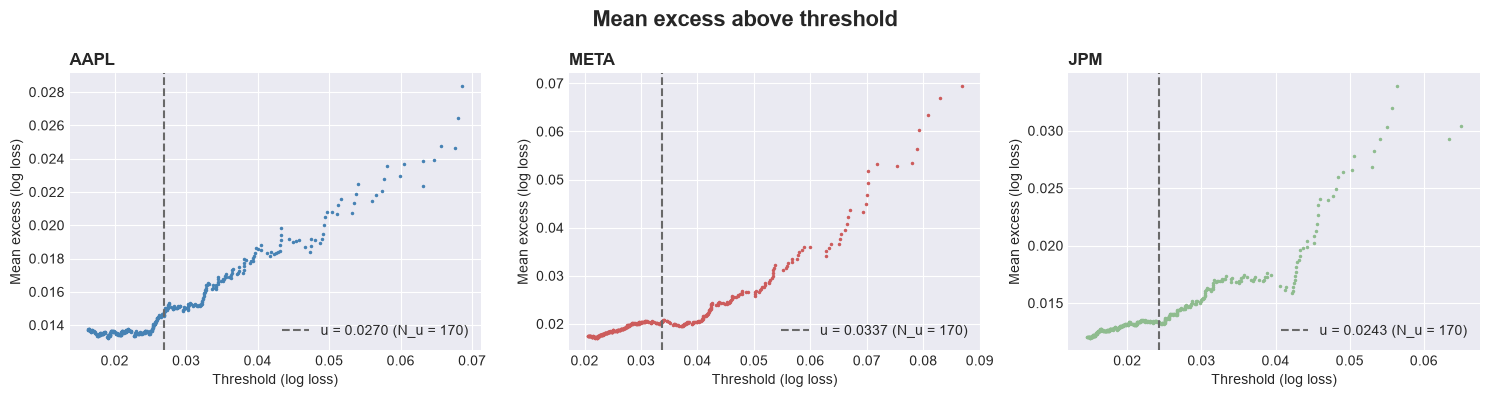

In [22]:
# Plot
# We want to plot the mean of (Xi - v) for i in [2, n]

K = 400
MIN_EXC = 10

fig, axes = plt.subplots(1, len(full_loss.columns), figsize=(15, 4))
fig.suptitle("Mean excess above threshold", fontsize=16, fontweight="bold")
e, thresholds, u_dict, Nu_dict = {}, {}, {}, {}

for ax, name in zip(axes, full_loss.columns):

    data = full_loss[name].dropna()
    x = np.sort(data.values)[::-1] # Sort in descending order

    i = np.arange(1, len(x)) # Generate indexes
    e_vals = np.cumsum(x)[:-1]/i - x[1:] # Compute excess mean
    v_vals = x[1:] # Thresholds

    # Create a mask for the upper tail with min exceendance count
    mask = (i <= K) & (i >= MIN_EXC)
    e[name], thresholds[name] = e_vals[mask], v_vals[mask] # Save in dictionnary


    u = data.quantile(0.95, interpolation="lower") # Set the reference 95 % quantile
    u_dict[name] = u
    Nu_dict[name] = int((data > u).sum()) # Compute number of exceedances

    # Plot
    ax.plot(thresholds[name], e[name], ".", ms=3, color=STOCK_COLORS[name])
    ax.axvline(u, color="dimgray", ls="--", label=f"u = {u:.4f} (N_u = {Nu_dict[name]})")
    ax.set_title(name, loc="left", fontsize=12, fontweight="bold")
    ax.set_xlabel("Threshold (log loss)")
    ax.set_ylabel("Mean excess (log loss)")
    ax.legend()

fig.tight_layout()
fig.savefig(OUT_DIR / "Q6_EVT.png", dpi=300)
plt.show()

### (c) Fitted GPD and empirical excess tail

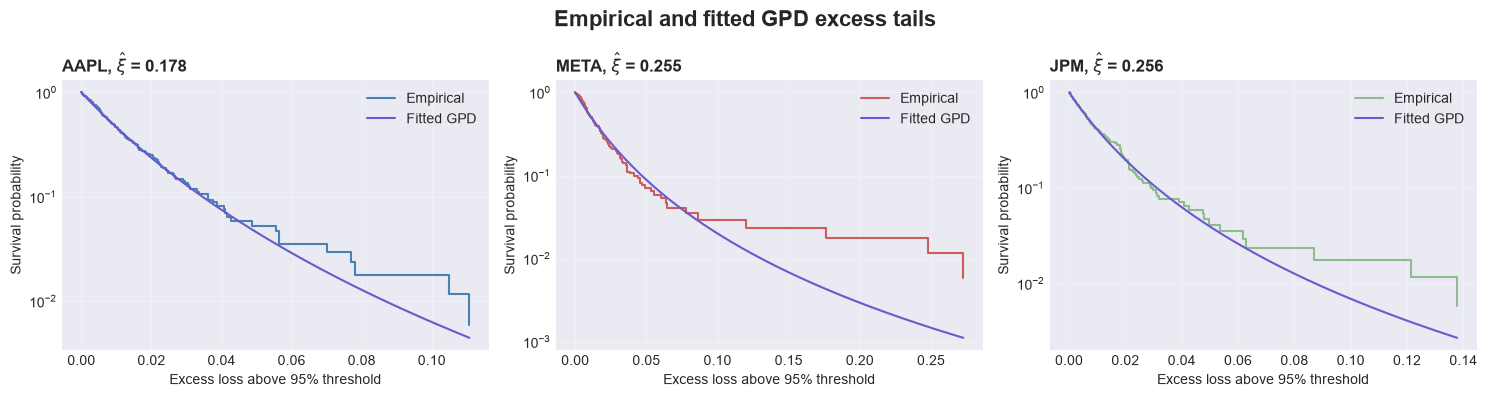

In [23]:
# Fit the excess tail above each stock's 95% threshold.
params = {}
names = full_loss.columns.tolist()
fig, axes = plt.subplots(1, len(names), figsize=(15, 4))
fig.suptitle("Empirical and fitted GPD excess tails", fontsize=16, fontweight="bold")

for ax, name in zip(axes, names):
    excess = (full_loss[name][full_loss[name] > u_dict[name]] - u_dict[name]).sort_values()
    shape, loc, scale = genpareto.fit(excess, floc=0)
    params[name] = (shape, loc, scale)

    # Survival probability at each observed excess.
    empirical = np.arange(len(excess), 0, -1) / len(excess)
    ax.step(excess, empirical, where="post", color=STOCK_COLORS[name], label="Empirical")
    grid = np.linspace(0, excess.max(), 300)
    ax.plot(grid, genpareto.sf(grid, shape, loc=0, scale=scale),
            color=METHOD_COLORS["Fitted GPD"], label="Fitted GPD")
    ax.set_title(rf"{name}, $\hat\xi$ = {shape:.3f}", loc="left", fontweight="bold")
    ax.set_xlabel("Excess loss above 95% threshold")
    ax.set_ylabel("Survival probability")
    ax.set_yscale("log")
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.tight_layout()
fig.savefig(OUT_DIR / "Q6_3_fittedGPD.png", dpi=300)
plt.show()

Under the fitted GPD tail, a positive shape $\hat\xi$ gives a finite fourth moment only if $4\hat\xi<1$. The estimates are 0.178 for AAPL, 0.255 for META, and 0.256 for JPM. The fitted model therefore has a finite fourth moment for AAPL, but not for META or JPM. These estimates suggest that the fourth-moment condition behind the Ljung–Box test on squared returns may fail for META and JPM; they do not prove that the true return distributions have infinite fourth moments. The empirical-versus-fitted survival plots also show that the far tail is uncertain. In particular, the META and JPM threshold diagnostics in (b) weaken confidence in extrapolating their fitted GPDs to 99.9%.

### (d–e) Deep-tail VaR and ES

For $x>u$, use $\bar F(x)\approx(N_u/n)[1+\xi(x-u)/\beta]^{-1/\xi}$. Setting this equal to $1-\alpha$ and solving for $x$ gives
$\widehat{\mathrm{VaR}}_\alpha=u+\frac{\hat\beta}{\hat\xi}\left[\left(\frac{N_u}{n(1-\alpha)}\right)^{\hat\xi}-1\right]$.
The GPD mean excess above that VaR gives
$\widehat{\mathrm{ES}}_\alpha=\widehat{\mathrm{VaR}}_\alpha+\frac{\hat\beta+\hat\xi(\widehat{\mathrm{VaR}}_\alpha-u)}{1-\hat\xi}$, provided $\hat\xi<1$. The direct-formula and fitted-CDF calculations below agree.

In [24]:
# Recall Nu_dict contains number of exceedance 
# and params contains the fitted GPD parameters

compare = {}
var_es_results = []

for name in full_loss:

    n = full_loss[name].shape[0]
    u = u_dict[name]
    Nu = Nu_dict[name]
    param = params[name]
    shape, scale = param[0], param[2]


    # 1. First we compute VaR and ES through the CDF
    r = n/Nu * (1 - DEEP_ALPHA)
    var_cdf = u + genpareto.isf(r, c=shape, loc=0, scale=scale)
    es_cdf = var_cdf + (scale + shape *(var_cdf - u))/(1 - shape)

    # 2. Compute VaR and ES through A.5 formulas
    # Use DEEP_ALPHA

    var_direct = u + scale/shape * ((n * (1 - DEEP_ALPHA)/Nu)**(-shape) - 1)
    es_direct = var_direct/(1 - shape) + (scale - u * shape)/(1 - shape)

    compare[name] = {
        "VaR from fitted CDF": var_cdf,
        "VaR direct": var_direct,
        "ES from fitted tail": es_cdf,
        "ES direct": es_direct,
    }

    # 4. Save results
    var_es_results.append({
        'method' : 'Fitted GPD', 'stock' : name,
        'alpha' : DEEP_ALPHA, 'VaR' : var_cdf, 'ES' : es_cdf
    })

display(pd.DataFrame(compare))

# Question 6 (e) (same code as question 2)
window_losses = losses        # one column per stock
alphas = [DEEP_ALPHA]

# (a) Gaussian
for elem in window_losses:
    mu = window_losses[elem].mean()
    sigma = window_losses[elem].std(ddof=1)
    for alpha in alphas:
        var = mu + sigma * stats.norm.ppf(alpha)
        es = mu + sigma * stats.norm.pdf(stats.norm.ppf(alpha)) / (1 - alpha)
        method = "Gaussian"
        var_es_results.append({
            "method": method, "stock": elem, "alpha": alpha,
            "VaR": var, 
            "ES": es,
        })

# (b) Student-t
t_params = {}
for elem in window_losses:
    lw = window_losses[elem]
    nu, mu_t, sig_t = stats.t.fit(lw.to_numpy())
    t_params[elem] = (nu, mu_t, sig_t)
    for alpha in alphas:
        q = stats.t.ppf(alpha, nu)
        var = mu_t + sig_t * q
        es = mu_t + sig_t * stats.t.pdf(q, nu) / (1.0 - alpha) * (nu + q**2) / (nu - 1.0)
        method = "Student-t"
        var_es_results.append({
            "method": method, "stock": elem, "alpha": alpha,
            "VaR": var,
            "ES": es
        })

var_es_results_df = pd.DataFrame(var_es_results).set_index("method")

,AAPL,META,JPM
VaR from fitted CDF,0.095757,0.133871,0.091260
VaR direct,0.095757,0.133871,0.091260
ES from fitted tail,0.125446,0.188130,0.127706
ES direct,0.125446,0.188130,0.127706


In [25]:
DEEP_METHODS = (*METHODS[1:], "Fitted GPD")

# Long format -> one row per stock, columns (measure, method), in daily log-loss percent units
df = var_es_results_df.reset_index()
tbl = (df.pivot(index="stock", columns="method", values=["VaR", "ES"])
         .reindex(columns=DEEP_METHODS, level=1) * 100)

# 1) Main comparison table (daily log loss (%))
print(f"Full-sample {DEEP_ALPHA:.1%} VaR and ES (daily log loss, %)")
display(tbl.round(2))

# 2) Percent difference of Gaussian and Student-t relative to the GPD
rel = pd.DataFrame({
    (m, meth): (tbl[(m, meth)] / tbl[(m, "Fitted GPD")] - 1) * 100
    for m in ["VaR", "ES"] for meth in METHODS[1:]
})
print("Difference to the GPD estimate (percent of the GPD value)")
display(rel.round(1))

# 3) Which model gives the lowest VaR and ES, per stock
lowest = pd.DataFrame({
    "Lowest VaR": tbl["VaR"].idxmin(axis=1),
    "Lowest ES":  tbl["ES"].idxmin(axis=1),
})
print("Lowest model per stock")
display(lowest)

Full-sample 99.9% VaR and ES (daily log loss, %)


VaR                            ES                     
method Gaussian Student-t Fitted GPD Gaussian Student-t Fitted GPD
stock                                                             
AAPL       5.41     10.42       9.58     5.91     15.17      12.54
JPM        4.97      9.48       9.13     5.42     13.93      12.77
META       7.35     13.71      13.39     8.02     20.27      18.81

Difference to the GPD estimate (percent of the GPD value)


VaR                 ES          
      Gaussian Student-t Gaussian Student-t
stock                                      
AAPL     -43.5       8.9    -52.9      20.9
JPM      -45.5       3.9    -57.5       9.1
META     -45.1       2.4    -57.4       7.7

Lowest model per stock


,Lowest VaR,Lowest ES
stock,,
AAPL,Gaussian,Gaussian
JPM,Gaussian,Gaussian
META,Gaussian,Gaussian


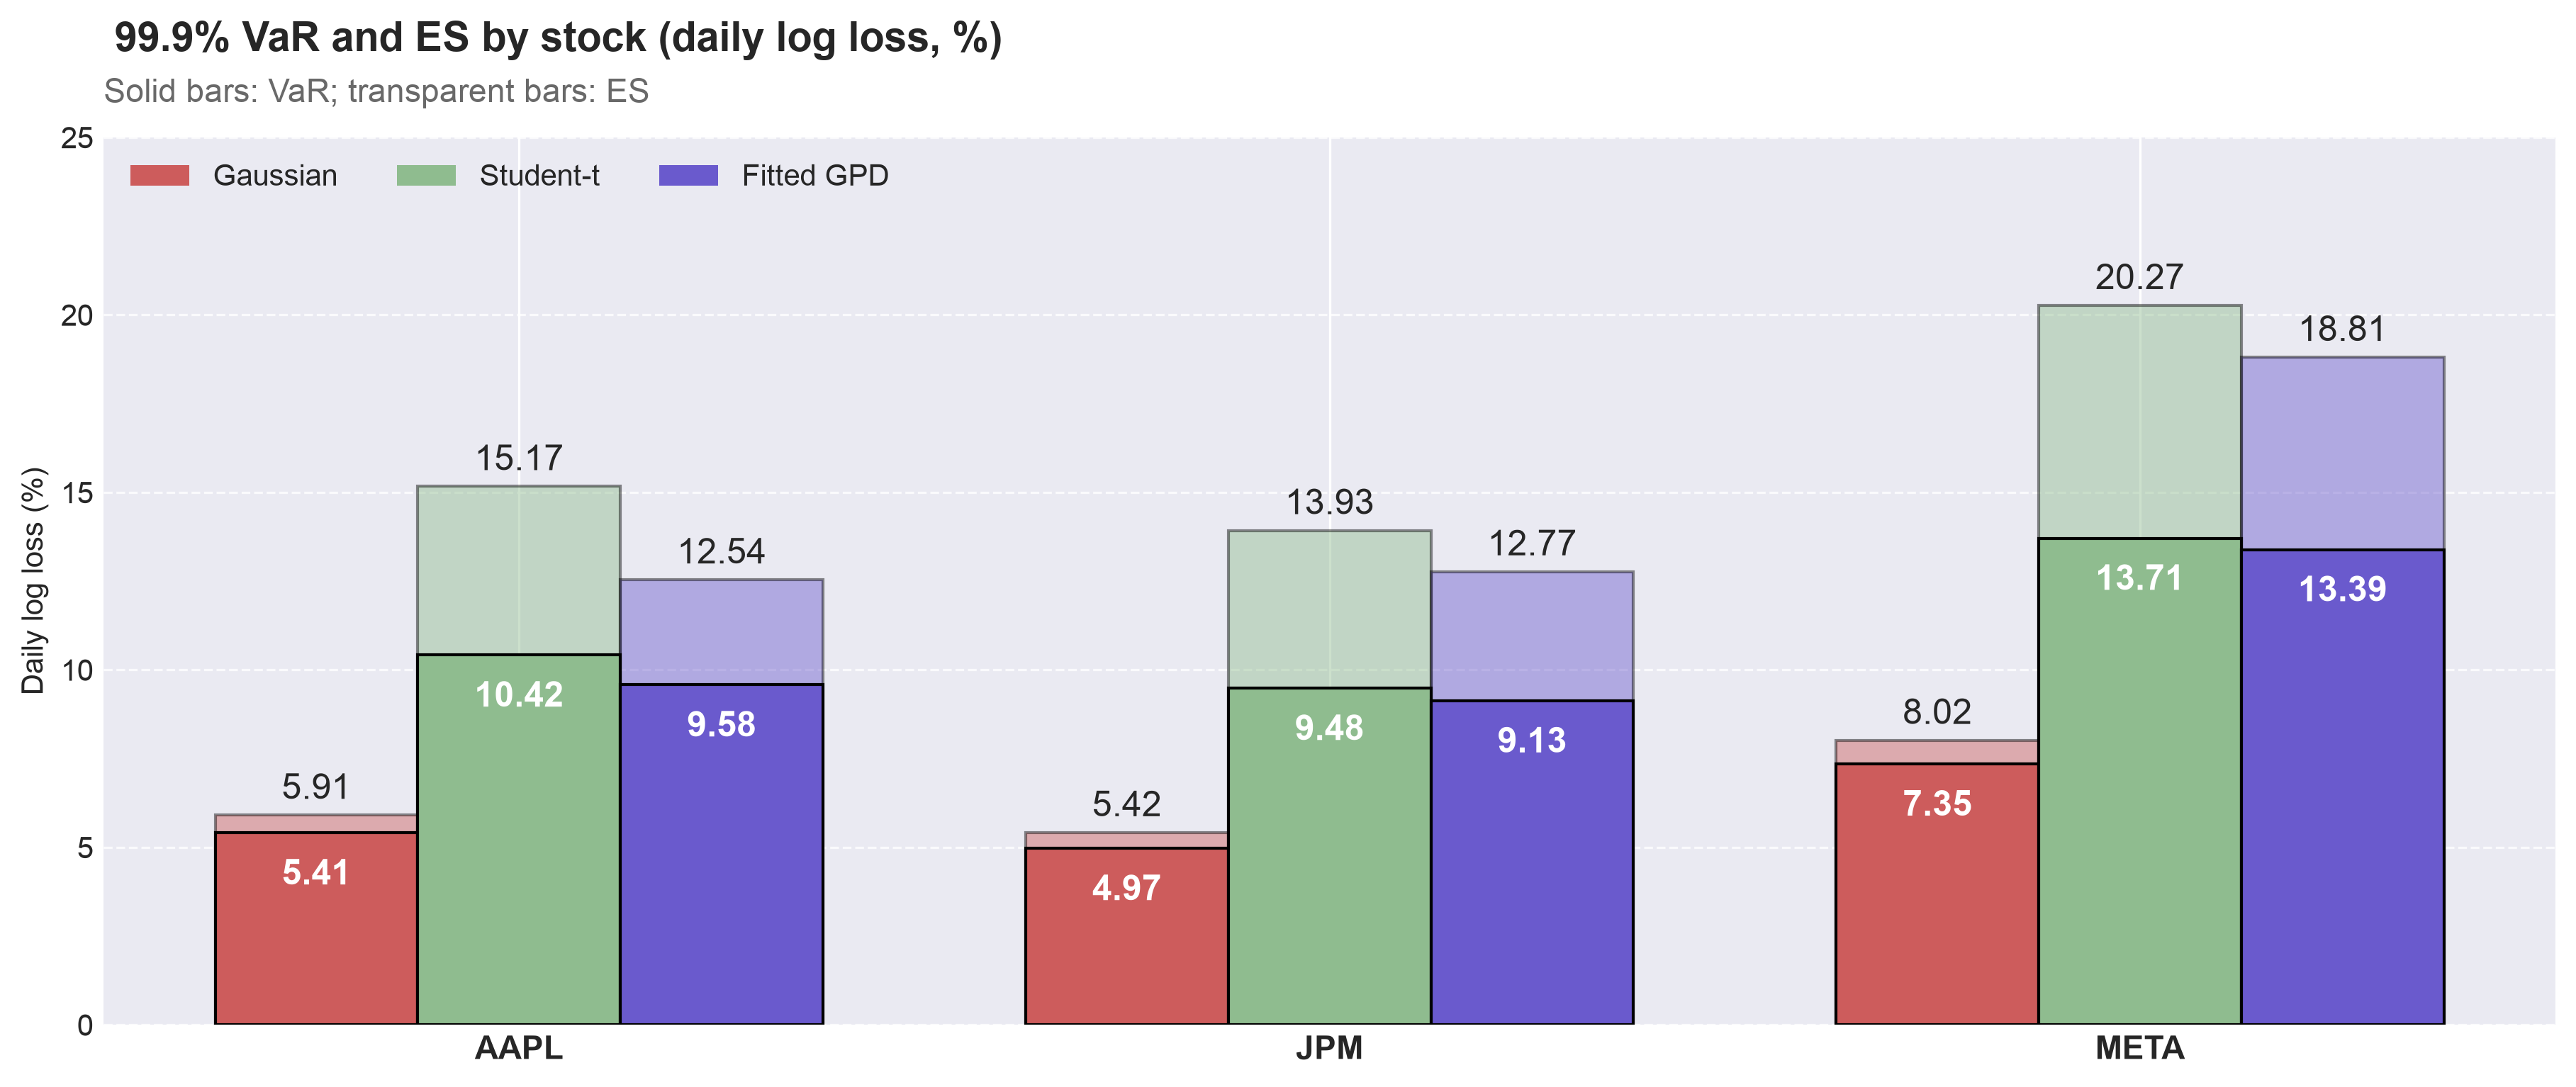

In [26]:
from matplotlib.patches import Patch

stocks = tbl.index.to_list()
stock_var = tbl['VaR'].round(2)
stock_es = tbl['ES'].round(2)

# Named Matplotlib colors, shared with the other figures.
colors_var = [METHOD_COLORS[method] for method in stock_var.columns]
colors_es = [METHOD_COLORS[method] for method in stock_es.columns]

# Initiate objects
fig, ax1 = plt.subplots(1, 1, figsize=(12, 5), layout='constrained', dpi=300)

# Plot title
fig.suptitle(
    "99.9% VaR and ES by stock (daily log loss, %)",
    fontsize=14,
    fontweight='bold',
    x=0.04, ha='left'
)

# Subtitle right underneath explaining the visual encoding
ax1.set_title(
    'Solid bars: VaR; transparent bars: ES',
    fontsize=11,
    color="dimgray",
    loc='left',
    pad=12
)

# Grid handling
ax1.grid(True, axis='y', linestyle = '--', alpha = 0.8)
ax1.spines[['top', 'right']].set_visible(False)
ax1.set_ylim(0, 25)
ax1.set_ylabel("Daily log loss (%)")

# Generate the grouped bar plot
res1 = ax1.grouped_bar(stock_var, tick_labels=stocks, group_spacing=1, colors = colors_var, zorder = 2, edgecolor = 'black')
res2 = ax1.grouped_bar(stock_es, tick_labels = stocks, group_spacing=1, colors = colors_es, alpha=0.45, zorder = 1, edgecolor = 'black')

# Plot the values
for container in res1.bar_containers:
    ax1.bar_label(container, padding=-20, color='white', fontweight='bold', fontsize=12)

for container in res2.bar_containers:
    ax1.bar_label(container, padding=3, fontsize=12)

# Style for x label (stocks name)
ax1.tick_params(axis='x', labelsize=11)
plt.setp(ax1.get_xticklabels(), fontweight='bold')

# Custom legend so both the distributions (colors) and VaR vs. ES (opacity) are clear
legend_handles = [
    Patch(facecolor=color, label=method)
    for color, method in zip(colors_var, stock_var.columns)
]
ax1.legend(handles=legend_handles, loc='upper left', ncols=3)

fig.savefig(OUT_DIR / "Q6_VaR_ES.png", dpi=300)
plt.show()

At 99.9%, the Gaussian has the lowest VaR and ES for every stock. Relative to the fitted GPD, its VaR is lower by 43.5%–45.5% and its ES by 52.9%–57.5%. The Gaussian tail decays much faster than the fitted heavy GPD tail, which explains the disagreement between these estimates. These percentages are differences relative to the fitted GPD, not proven underestimation of actual tail risk. Student-t estimates are above the GPD estimates for all three stocks. These are extrapolations from only 170 excesses per stock to a level with roughly three or four observations in the entire sample; the GPD estimate and the percentage gaps are sensitive to the threshold and tail fit.

## Question 7 -- Recommendation

| Stock | 97.5% VaR | 99% VaR | ES assessment |
|:--|:--|:--|:--|
| AAPL | Student-t GARCH, provisionally | Quantile regression | Student-t GARCH has the best FZ score, but its ES Z test rejects ($p_Z=0.0107$). |
| META | Student-t GARCH | Student-t GARCH | Both VaR levels pass coverage, independence, and conditional coverage; its ES Z test still rejects ($p_Z=0.0069$). |
| JPM | Student-t GARCH is the best available candidate, not production ready | Student-t GARCH is the best available candidate, not production ready | No tested method passes all VaR validation criteria at either level; exception independence fails for Student-t GARCH at both, and its ES Z test rejects ($p_Z=0.0048$). |

Student-t GARCH minimizes out-of-sample pinball loss for all six stock-level pairs and the FZ score for all three stocks at 97.5%. For AAPL at 97.5%, these relative advantages make it the best available candidate, not an adequately calibrated VaR model: unconditional coverage rejects ($p_{uc}=0.0130$) and conditional coverage also rejects ($p_{cc}=0.0456$). At AAPL 99%, quantile regression is preferable for VaR because it passes all three VaR backtests, whereas Student-t GARCH fails coverage despite its lower pinball loss. The provisional choices fail at least one VaR backtest and need recalibration before unrestricted use. For JPM, none of the tested methods meets all VaR validation criteria at either level; the best-ranked candidate should not be treated as suitable for actual production. No evaluated ES model passes the ES backtest for AAPL or JPM; for META, Historical passes the ES test but ranks below Student-t GARCH by FZ score and has clustered VaR exceptions at 97.5%. I would therefore not deploy any ES forecast without further tail calibration and a fresh validation period. The reported GARCH performance is conditional on full-sample AR-order selection, which used evaluation-period data. An unbiased production decision requires selecting the order before evaluation and confirming performance in a genuinely untouched sample.